# Bounce optical state from A–B–A: all DZ, v-modes and DOF vs elevation (v1)

**Author:** Aaron Roodman (with Claude)  
**Date Created:** 2026-10-29  
**Last Modified:** 2026-10-29  
**Status:** In Progress  
**Keywords:** bounce, A–B–A, DZ, v-modes, DOF, RBR, red noise, BLOCK-T720  

## Description

The BLOCK-T720 elevation sweep (reference 70 deg), with every quantity from one
analysis:

1. The A–B–A Δ of all 126 DZ_kj terms (k = 1–6, the 21 pupil j) for each
   (night, leg): the median over B visits of B minus the A interpolated to its
   time from its neighbours.
2. The 50 DOF from Range-Bounded Recovery (RBR) 50/50 of that ΔDZ vector, with the
   bounce run's knobs.
3. Those DOF in the 50-DOF, 50-mode v-modes of `rubinwork.aos_state` (first 34 shown).

Errors come from one Monte Carlo of the full DZ vector. The red-noise model of
`bounce_delta_derivation_v3` is generalised from one term to 126: a white
covariance `Σ_W` and a red covariance `Σ_R` (each 126 × 126) with one shared time
exponent ALPHA, fit to the multivariate variogram. Each MC draw of the visits'
DZ vectors goes through A–B–A, then RBR, then the v-mode map, so the errors carry
the covariance between DZ terms and the nonlinearity of RBR.

**Output:** `bounce_aba_optical_state.pdf` (DZ, v-mode and DOF pages) and CSVs in
the study run directory.

**Based on:** `aos/bounce/study.md`, Log 2026-10-29 (DZ(1,4) and v1 put 40 deg
out of family; the error model of `bounce_delta_derivation_v3`/`v4`).

## Change Log

| Date | Author | Description |
|------|--------|-------------|
| 2026-10-29 | Aaron Roodman | Initial version |

## Table of Contents

1. [Parameters](#params)
2. [Setup & Imports](#setup)
3. [Data Access](#data)
4. [Visits and legs](#visits)
5. [Multivariate red-noise model](#model)
6. [A–B–A Δ, RBR and Monte Carlo errors](#mc)
7. [Why the DOF do not show the v1 pattern](#dofsplit)
8. [Plots: DZ, v-modes, DOF vs elevation](#plots)
9. [Save](#save)

<a id='params'></a>
## Parameters

In [1]:
DAY_OBS = [20260418, 20260419, 20260513, 20260709, 20260711, 20260713]
BOUNCE = 'T720_elevation'          # bounce name from analysis_config.yaml

PARAM_SET = 'danish_1_3'
MI_NAME = 'pathA_50_50_i_rbr_5rot'
MIW_VARIANT = 'd13-A_50_50_i_rbr_5rot'
MIW_BUILD = '20261028b'
MIN_DETECTORS = 160                # the bounce run's --min-detectors

T0_MIN = 10.0                      # red-noise reference lag, min
LAG_BINS = [0, 4, 8, 15, 30, 60, 120]   # same-setting variogram bins, min
ALPHA_GRID = (0.5, 2.0, 0.05)      # scan of the shared red-noise exponent (dimensionless)
N_MC = 1000                        # MC realisations per (night, leg)
N_VMODES_SHOW = 34
J_PER_PAGE = 4                     # DZ pages: k = 1..6 across, this many j down
VMODES_PER_PAGE = 12
DOF_PER_PAGE = 10
SEED = 20261029
SAVE = True

from rubinwork.common import study_run
run = study_run('aos/bounce', 'aba_optical_state')

<a id='setup'></a>
## Setup & Imports

In [2]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.backends.backend_pdf import PdfPages
from scipy.optimize import least_squares

from rubinwork import aos_state
from rubinwork.bounce import legs as bl
from rubinwork.bounce import analysis as ba
from rubinwork.common.utils import repo_root
from rubinwork.products import catalog
from lsst.ts.intrinsic.wavefront.ofc_svd import (build_ofc_svd, project_dz_table,
                                                 LABELS_50DOF, DOF_UNITS_50)

pd.set_option('display.width', 200)
pd.set_option('display.max_columns', 30)

<a id='data'></a>
## Data Access

The fit table goes through the same bad-fit drop and quality cut as the bounce run.

In [3]:
cfg = bl.resolve_config(PARAM_SET, MI_NAME,
                        analysis_config=repo_root() / 'aos' / 'analysis_config.yaml')
prefix = cfg['fit_prefix']
b = next(x for x in cfg['bounces'] if x['name'] == BOUNCE)
ft = ba.load_fit_table(catalog.path('miw', MIW_VARIANT, build=MIW_BUILD) / 'fits.parquet',
                       cfg, min_detectors=MIN_DETECTORS)
iZs = list(cfg['pupil_j_range']); kr = cfg['focal_k_range']
svd = build_ofc_svd(iZs, int(min(kr)), int(max(kr)), int(cfg['rbr_n_keep']), n_dof=cfg['n_dof'],
                    ofc_normalization_yaml=cfg['ofc_normalization_yaml'])
_, _, _, W = project_dz_table(ft, prefix, svd)      # (visit, kj) um of wavefront
KJ = list(svd.kj_grid); NT = len(KJ)
se50 = aos_state.make_state_estimator(dof_set='all_50', n_modes=50)
# DOF -> v-mode is linear, so one (DOF, v-mode) matrix does every draw
T_V = aos_state.vmodes_from_dofs(np.eye(50), se50, n_modes=50)

def rbr(w):
    return svd.estimator.dof_range_bounded(
        w, kappa=float(cfg['rbr_kappa']), power=int(cfg['rbr_power']),
        penalty_weight=float(cfg['rbr_penalty_weight']), full_dof=bool(cfg['rbr_full_dof']))

print(f'{len(ft)} visits, {NT} DZ terms (k = {min(kr)}..{max(kr)}, j = {iZs}); RBR kappa = '
      f'{cfg["rbr_kappa"]}, power = {cfg["rbr_power"]}, penalty_weight = {cfg["rbr_penalty_weight"]}, '
      f'full_dof = {cfg["rbr_full_dof"]}')

  dropping 11 bad-flagged visits (z1toz6_bad_fit)


        Use pytest instead. [astropy.tests.runner]
        Use pytest instead.


        Use pytest instead. [astropy.utils.decorators]
        Use pytest instead.


INFO:lsst.ts.utils.tai:Update leap second table


INFO:lsst.ts.utils.tai:current_tai uses the system TAI clock


  quality cut (min_detectors=160): 1575/2012 visits kept


1575 visits, 126 DZ terms (k = 1..6, j = [4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 22, 23, 24, 25, 26]); RBR kappa = 4.0, power = 3, penalty_weight = 1.0, full_dof = True


<a id='visits'></a>
## Visits and legs

`run_bounce(..., day_obs=night)` gives the A mask and each B leg's mask, as in the
bounce run. A–B–A uses every A and B visit of the leg in time order.

In [4]:
dobs = np.asarray(ft['day_obs']).astype(int)
seq = np.asarray(ft['seq_num']).astype(int)
mjd = np.asarray(ft['mjd'], float)
prog = bl.bounce_program_mask(ft, b)
visits, pair_rows, legs = [], [], []
for d in DAY_OBS:
    rb = bl.run_bounce(ft, b, prefix, [1], [4], day_obs=d)
    night = (dobs == d) & prog
    if not night.any():
        continue
    t0 = mjd[night].min()
    for lab, cb in rb['comparisons'].items():
        if not cb['pairs']:
            continue
        legs.append({'night': d, 'leg': lab, 'b_value_deg': bl.leg_b_value(lab)})
        for i in np.nonzero(night)[0]:
            s = 'A' if rb['ref_mask'][i] else 'B' if cb['comp_mask'][i] else 'other'
            visits.append({'night': d, 'leg': lab, 'row': i, 'seq_num': seq[i],
                           't_min': (mjd[i] - t0) * 1440.0, 'setting': s})
        for r, c in cb['pairs']:
            pair_rows.append({'night': d, 'leg': lab, 'row_A': r, 'row_B': c,
                              'lag_min': (mjd[c] - mjd[r]) * 1440.0})
vdf = pd.DataFrame(visits)
pdf_pairs = pd.DataFrame(pair_rows)


def leg_visits(d, lab):
    v = vdf[(vdf.night == d) & (vdf.leg == lab) & vdf.setting.isin(['A', 'B'])]
    return v.drop_duplicates('seq_num').sort_values('seq_num')


def aba_matrix(v):
    # rows: each A–B–A difference as weights on the visits of v
    s = v.setting.to_numpy(); t = v.t_min.to_numpy(); A = np.nonzero(s == 'A')[0]
    rows = []
    for i in np.nonzero(s == 'B')[0]:
        a0 = A[A < i]; a1 = A[A > i]
        if len(a0) and len(a1):
            a0, a1 = a0[-1], a1[0]; f = (t[i] - t[a0]) / (t[a1] - t[a0])
            w = np.zeros(len(s)); w[i] = 1; w[a0] -= 1 - f; w[a1] -= f
            rows.append(w)
    return np.array(rows)


legs_df = pd.DataFrame(legs)
legs_df['n_A'] = [(leg_visits(r.night, r.leg).setting == 'A').sum() for r in legs_df.itertuples()]
legs_df['n_B'] = [(leg_visits(r.night, r.leg).setting == 'B').sum() for r in legs_df.itertuples()]
legs_df['n_aba'] = [len(aba_matrix(leg_visits(r.night, r.leg))) for r in legs_df.itertuples()]
legs_df

,night,leg,b_value_deg,n_A,n_B,n_aba
0,20260418,Elev=40,40.0,6,6,5
1,20260419,Elev=40,40.0,12,10,9
2,20260513,Elev=40,40.0,8,8,7
3,20260709,Elev=60,60.0,6,4,3
4,20260711,Elev=50,50.0,6,6,5
5,20260713,Elev=30,30.0,12,5,5
6,20260713,Elev=75,75.0,12,6,6


<a id='model'></a>
## Multivariate red-noise model

The v3 model for one term, `D(tau) = 2 SIGMA_W^2 + SIGMA_R^2 (tau / T0)^ALPHA`,
becomes a matrix model for the 126-term DZ vector:

`D(tau) = 2 Σ_W + Σ_R (tau / T0)^ALPHA`, where `D_ab(tau) = <Δy_a Δy_b>` over visit pairs at lag tau.

The data are as in v3: the B − A pair residuals about each (night, leg) median
(scaled by sqrt(n / (n − 1))), and the same-setting visit differences in lag bins.
ALPHA is shared by all terms, which keeps the model a valid covariance. For
each ALPHA on a grid, `Σ_W` and `Σ_R` are a weighted linear fit, element by
element. The ALPHA with the least summed diagonal chi2 is kept. Each matrix is
then projected to the nearest positive semidefinite one (negative eigenvalues set
to 0).

Element errors: `var(D_ab) = (D_aa D_bb + D_ab^2) / n`, the Gaussian value.

variogram points: [('B−A pairs', np.int64(45)), ('same-setting 4-8 min', np.int64(77)), ('same-setting 8-15 min', np.int64(61)), ('same-setting 15-30 min', np.int64(125)), ('same-setting 30-60 min', np.int64(90)), ('same-setting 60-120 min', np.int64(16))]
ALPHA = 1.1 (dimensionless); summed diagonal chi2/dof = 1469.4/503
negative-eigenvalue sum over positive sum: Σ_W 0.077, Σ_R 0.124 (dimensionless, before projection)
DZ(1,4): sigma_W = 0.0188 um, sigma_R = 0.1328 um over 10 min (v3 single-term fit: 0.035 um, 0.104 um, ALPHA = 1.62)


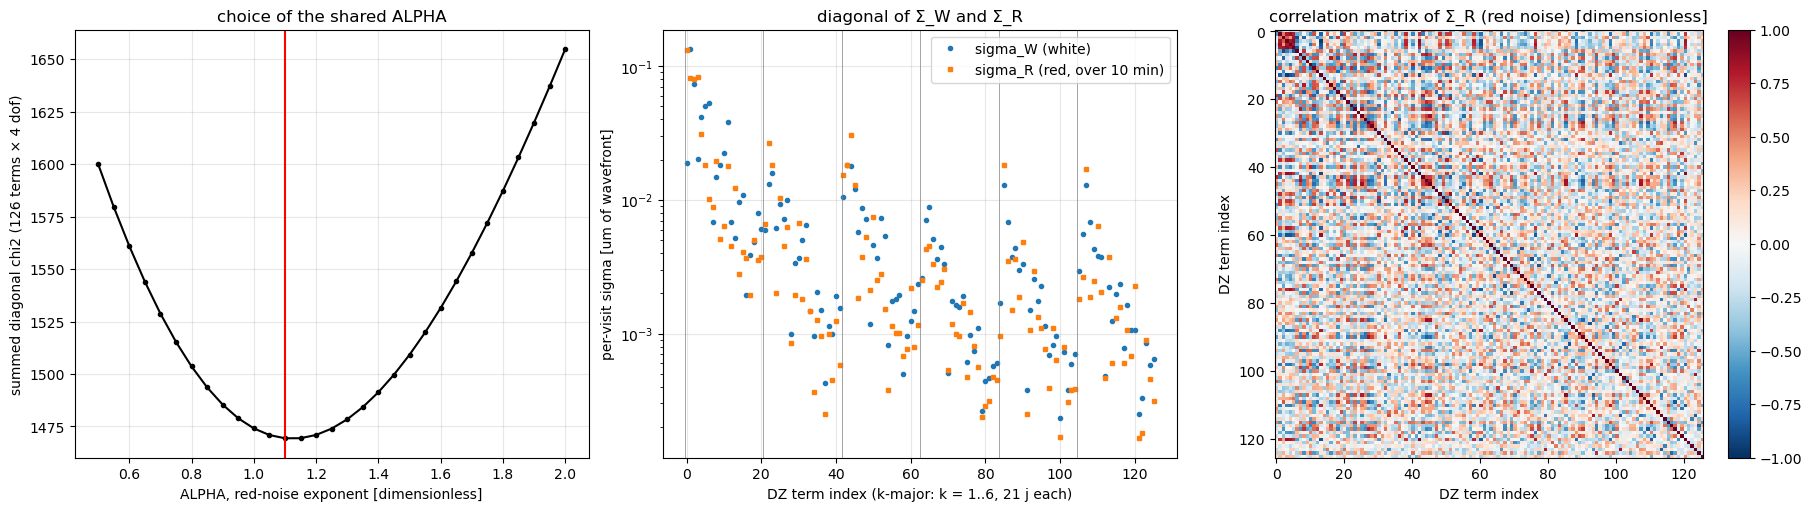

,term,sigma_W_um,sigma_R_um,chi2_vg,dof_vg
0,"DZ(1,4)",0.018822,0.13278,8.384597,4


In [5]:
vv = vdf[vdf.setting.isin(['A', 'B'])].drop_duplicates(['night', 'seq_num'])
dys, lags = [], []
for (n, s), g in vv.groupby(['night', 'setting']):
    g = g.sort_values('t_min'); tt = g.t_min.to_numpy(); rr = g.row.to_numpy()
    for i in range(len(rr)):
        for j in range(i + 1, len(rr)):
            dys.append(W[rr[j]] - W[rr[i]]); lags.append(tt[j] - tt[i])
dys = np.array(dys); lags = np.array(lags)
dp = W[pdf_pairs.row_B] - W[pdf_pairs.row_A]
dc = np.zeros_like(dp)
for _, ix in pdf_pairs.groupby(['night', 'leg']).indices.items():
    dc[ix] = (dp[ix] - np.median(dp[ix], 0)) * np.sqrt(len(ix) / (len(ix) - 1))
Dm, nb, tb, src = [dc.T @ dc / len(dc)], [len(dc)], [pdf_pairs.lag_min.median()], ['B−A pairs']
bi = np.digitize(lags, LAG_BINS) - 1
for k in range(len(LAG_BINS) - 1):
    m = bi == k
    if m.sum() >= 5:
        Dm.append(dys[m].T @ dys[m] / m.sum()); nb.append(int(m.sum())); tb.append(np.median(lags[m]))
        src.append(f'same-setting {LAG_BINS[k]}-{LAG_BINS[k + 1]} min')
Dm = np.array(Dm); nb = np.array(nb); tb = np.array(tb)
dg = np.einsum('kaa->ka', Dm)
Derr = np.sqrt((dg[:, :, None] * dg[:, None, :] + Dm ** 2) / nb[:, None, None])


def fit_given_alpha(alpha):
    X = np.column_stack([np.full(len(tb), 2.0), (tb / T0_MIN) ** alpha])
    Wt = 1 / Derr ** 2
    A11 = np.einsum('k,kab->ab', X[:, 0] ** 2, Wt)
    A12 = np.einsum('k,kab->ab', X[:, 0] * X[:, 1], Wt)
    A22 = np.einsum('k,kab->ab', X[:, 1] ** 2, Wt)
    b1 = np.einsum('k,kab->ab', X[:, 0], Wt * Dm); b2 = np.einsum('k,kab->ab', X[:, 1], Wt * Dm)
    det = A11 * A22 - A12 ** 2
    SW = (A22 * b1 - A12 * b2) / det; SR = (A11 * b2 - A12 * b1) / det
    model = X[:, 0, None, None] * SW + X[:, 1, None, None] * SR
    return SW, SR, np.einsum('kaa->a', ((model - Dm) / Derr) ** 2)


def nearest_psd(M):
    e, U = np.linalg.eigh(0.5 * (M + M.T))
    return (U * np.clip(e, 0, None)) @ U.T, e


alphas = np.round(np.arange(ALPHA_GRID[0], ALPHA_GRID[1] + 1e-9, ALPHA_GRID[2]), 3)
tot = np.array([fit_given_alpha(a)[2].sum() for a in alphas])
ALPHA = float(alphas[np.argmin(tot)])
SW_raw, SR_raw, chi2_vg = fit_given_alpha(ALPHA)
SIG_W, eW = nearest_psd(SW_raw); SIG_R, eR = nearest_psd(SR_raw)
dof_vg = len(tb) - 2
i14 = KJ.index((1, 4))
print(f'variogram points: {list(zip(src, nb))}')
print(f'ALPHA = {ALPHA} (dimensionless); summed diagonal chi2/dof = {tot.min():.1f}/{NT * dof_vg - 1}')
print(f'negative-eigenvalue sum over positive sum: Σ_W {-eW[eW < 0].sum() / eW[eW > 0].sum():.3f}, '
      f'Σ_R {-eR[eR < 0].sum() / eR[eR > 0].sum():.3f} (dimensionless, before projection)')
print(f'DZ(1,4): sigma_W = {np.sqrt(SIG_W[i14, i14]):.4f} um, sigma_R = {np.sqrt(SIG_R[i14, i14]):.4f} um '
      f'over {T0_MIN:g} min (v3 single-term fit: 0.035 um, 0.104 um, ALPHA = 1.62)')
vgm = pd.DataFrame({'term': [f'DZ({k},{j})' for k, j in KJ],
                    'sigma_W_um': np.sqrt(np.diag(SIG_W)), 'sigma_R_um': np.sqrt(np.diag(SIG_R)),
                    'chi2_vg': chi2_vg, 'dof_vg': dof_vg})

fig_vg, ax = plt.subplots(1, 3, figsize=(18, 5), layout='constrained')
ax[0].plot(alphas, tot, 'k.-'); ax[0].axvline(ALPHA, color='r')
ax[0].set_xlabel('ALPHA, red-noise exponent [dimensionless]')
ax[0].set_ylabel(f'summed diagonal chi2 ({NT} terms × {dof_vg} dof)')
ax[0].set_title('choice of the shared ALPHA'); ax[0].grid(alpha=0.3)
ax[1].semilogy(vgm.sigma_W_um, 'o', ms=3, label='sigma_W (white)')
ax[1].semilogy(vgm.sigma_R_um, 's', ms=3, label=f'sigma_R (red, over {T0_MIN:g} min)')
for x in range(0, NT, len(iZs)):
    ax[1].axvline(x - 0.5, color='gray', lw=0.5)
ax[1].set_xlabel('DZ term index (k-major: k = 1..6, 21 j each)')
ax[1].set_ylabel('per-visit sigma [um of wavefront]'); ax[1].legend(); ax[1].grid(alpha=0.3)
ax[1].set_title('diagonal of Σ_W and Σ_R')
sd = np.sqrt(np.diag(SIG_R)); im = ax[2].imshow(SIG_R / np.outer(sd, sd), cmap='RdBu_r', vmin=-1, vmax=1)
ax[2].set_title('correlation matrix of Σ_R (red noise) [dimensionless]')
ax[2].set_xlabel('DZ term index'); ax[2].set_ylabel('DZ term index')
plt.colorbar(im, ax=ax[2])
plt.show()
vgm.iloc[[i14]]

<a id='mc'></a>
## A–B–A Δ, RBR and Monte Carlo errors

Per (night, leg):

- ΔDZ is the median over the B visits of the A–B–A differences, term by term.
- ΔDOF = RBR(ΔDZ), and Δv = ΔDOF · T_V.
- For the MC, the visits' DZ vectors are replaced by a draw from the model, with
  the real visit times. The red part, `L_t Z L_R^T`, has time covariance
  `K(t, t') = (u^ALPHA + u'^ALPHA − |u − u'|^ALPHA) / 2` (u = t / T0) and term
  covariance `Σ_R`. The white part has covariance `Σ_W`.
- Each draw goes through the same A–B–A median, giving a noise draw δ. RBR is
  solved on ΔDZ + δ. The error on every quantity is the sd over N_MC draws.

RBR is nonlinear, so it is solved at the measured ΔDZ, not at 0. This is the
linearisation-free form of `J Σ J^T`.

In [6]:
LW = np.linalg.cholesky(SIG_W + 1e-12 * np.trace(SIG_W) / NT * np.eye(NT))
LR = np.linalg.cholesky(SIG_R + 1e-12 * np.trace(SIG_R) / NT * np.eye(NT))
rng = np.random.default_rng(SEED)
res = {}
t_s = time.time()
for L in legs:
    d, lab = L['night'], L['leg']
    v = leg_visits(d, lab); M = aba_matrix(v); Y = W[v.row.to_numpy()]
    dz = np.median(M @ Y, 0)
    u = (v.t_min.to_numpy() - v.t_min.min()) / T0_MIN
    Kt = 0.5 * (u[:, None] ** ALPHA + u[None, :] ** ALPHA - np.abs(u[:, None] - u[None, :]) ** ALPHA)
    Lt = np.linalg.cholesky(Kt + 1e-9 * np.eye(len(u)))
    Z1 = rng.normal(size=(N_MC, len(v), NT)); Z2 = rng.normal(size=(N_MC, len(v), NT))
    noise = np.einsum('ij,mjk,lk->mil', Lt, Z1, LR) + Z2 @ LW.T
    dz_mc = np.median(np.einsum('bi,mik->mbk', M, noise), 1)
    dof = rbr(dz)
    dof_mc = np.array([rbr(dz + x) for x in dz_mc])
    res[(d, lab)] = dict(dz=dz, dz_err=dz_mc.std(0, ddof=1), dof=dof, dof_mc=dof_mc,
                         dof_err=dof_mc.std(0, ddof=1), v=dof @ T_V,
                         v_err=(dof_mc @ T_V).std(0, ddof=1),
                         dof_bias=(dof_mc.mean(0) - dof) / dof_mc.std(0, ddof=1))
print(f'MC: {N_MC} draws × {len(legs)} legs in {time.time() - t_s:.0f} s')
mx_bias = max(np.nanmax(np.abs(r['dof_bias'])) for r in res.values())
print(f'largest |MC mean DOF − nominal DOF| / MC sd over all DOF and legs = {mx_bias:.2f} '
      f'(dimensionless; the RBR nonlinearity)')
rows = []
for L in legs:
    r = res[(L['night'], L['leg'])]
    rows.append({'night': L['night'], 'leg': L['leg'], 'b_value_deg': L['b_value_deg'],
                 'dDZ_1_4_um': r['dz'][i14], 'dDZ_1_4_err_um': r['dz_err'][i14],
                 'dv1': r['v'][0], 'dv1_err': r['v_err'][0],
                 'dM2_dz_um': r['dof'][0], 'dM2_dz_err_um': r['dof_err'][0],
                 'dCam_dz_um': r['dof'][5], 'dCam_dz_err_um': r['dof_err'][5],
                 'corr_M2dz_Camdz': np.corrcoef(r['dof_mc'][:, 0], r['dof_mc'][:, 5])[0, 1]})
key = pd.DataFrame(rows)
key.round(4)

MC: 1000 draws × 7 legs in 55 s
largest |MC mean DOF − nominal DOF| / MC sd over all DOF and legs = 1.46 (dimensionless; the RBR nonlinearity)


,night,leg,b_value_deg,dDZ_1_4_um,dDZ_1_4_err_um,dv1,dv1_err,dM2_dz_um,dM2_dz_err_um,dCam_dz_um,dCam_dz_err_um,corr_M2dz_Camdz
0,20260418,Elev=40,40.0,-0.0682,0.0261,-0.0075,0.0018,-70.2946,20.9001,57.0766,20.1557,-0.9952
1,20260419,Elev=40,40.0,-0.1219,0.0212,-0.0113,0.0014,-38.9478,17.0939,31.8564,16.4744,-0.9947
2,20260513,Elev=40,40.0,0.0086,0.0238,-0.0030,0.0016,-41.3845,25.3148,28.1129,22.5282,-0.9938
3,20260709,Elev=60,60.0,0.0703,0.0340,0.0064,0.0022,60.4782,33.2382,-51.2353,29.4850,-0.9911
4,20260711,Elev=50,50.0,0.1751,0.0266,0.0142,0.0018,-84.9448,35.8786,72.0010,30.9617,-0.9952
5,20260713,Elev=30,30.0,0.3660,0.0273,0.0195,0.0019,-30.4829,33.1750,0.8263,28.7253,-0.9941
6,20260713,Elev=75,75.0,0.0146,0.0231,0.0011,0.0015,-0.0861,36.1602,0.4652,30.5587,-0.9955


<a id='dofsplit'></a>
## Why the DOF do not show the v1 pattern

v1 = 1 is M2_dz = −464 um with Cam_dz = −646 um: mostly the two hexapod dz
moving together, which is focus. The difference of the two (M2 dz against
camera dz at fixed focus) is poorly constrained by the wavefront. So the noise
puts the two DOF on a long anticorrelated line.

Each DOF alone has a large error, and the measured values scatter along that
line. Their weighted sum, v1, is well measured. Below are the two hexapod dz
values per leg, with the MC 1-sigma ellipse and the line of constant v1 through
each point.

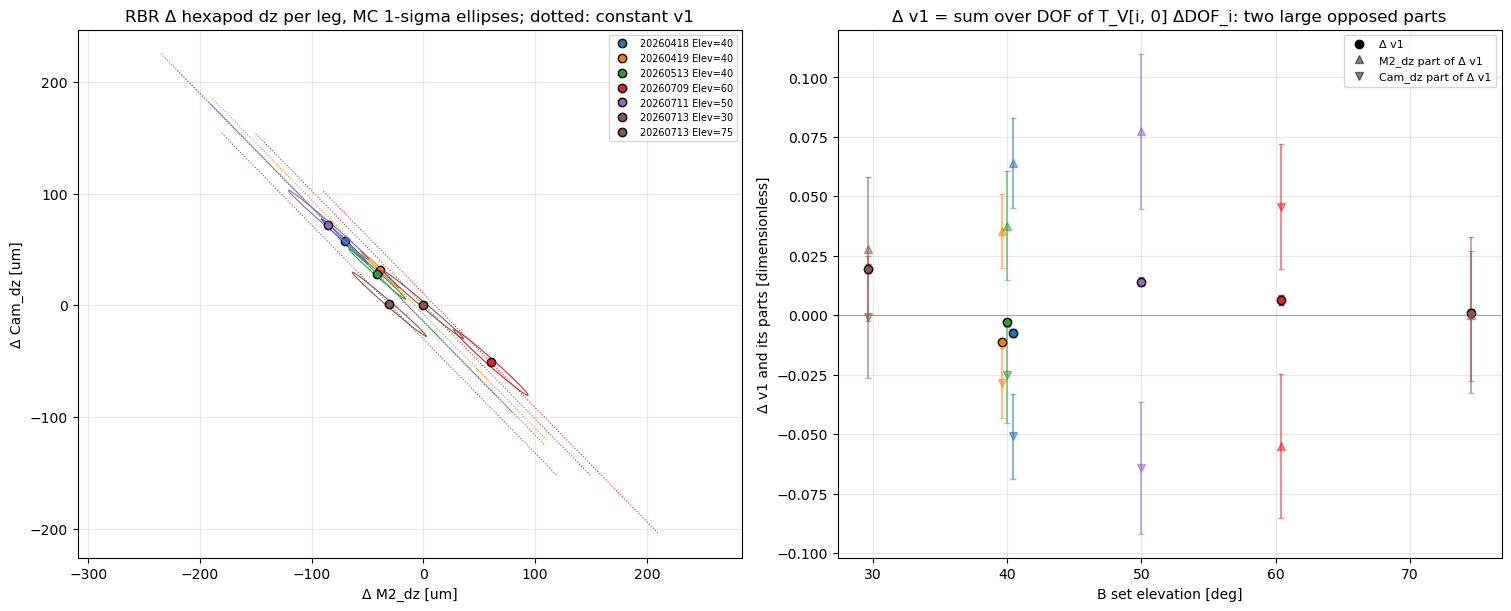

In [7]:
ncol = {n: plt.get_cmap('tab10')(i % 10) for i, n in enumerate(sorted({L['night'] for L in legs}))}
fig_split, ax = plt.subplots(1, 2, figsize=(15, 6), layout='constrained')
for L in legs:
    r = res[(L['night'], L['leg'])]; c = ncol[L['night']]
    x, y = r['dof'][0], r['dof'][5]
    C2 = np.cov(r['dof_mc'][:, [0, 5]].T); e, U = np.linalg.eigh(C2)
    th = np.linspace(0, 2 * np.pi, 100); el = U @ (np.sqrt(e)[:, None] * np.array([np.cos(th), np.sin(th)]))
    ax[0].plot(x + el[0], y + el[1], '-', color=c, lw=0.8)
    ax[0].plot(x, y, 'o', color=c, mec='k', label=f'{L["night"]} {L["leg"]}')
    s = np.linspace(-150, 150, 2)
    ax[0].plot(x + s, y - s * T_V[0, 0] / T_V[5, 0], ':', color=c, lw=0.8)
ax[0].set_xlabel('Δ M2_dz [um]'); ax[0].set_ylabel('Δ Cam_dz [um]')
ax[0].set_title('RBR Δ hexapod dz per leg, MC 1-sigma ellipses; dotted: constant v1')
ax[0].legend(fontsize=7); ax[0].grid(alpha=0.3); ax[0].axis('equal')
for L in legs:
    r = res[(L['night'], L['leg'])]
    ax[1].errorbar(L['b_value_deg'] + 0.4 * (L['night'] % 3 - 1), r['v'][0], yerr=r['v_err'][0], fmt='o',
                   color=ncol[L['night']], mec='k', capsize=2)
    ax[1].errorbar(L['b_value_deg'] + 0.4 * (L['night'] % 3 - 1),
                   r['dof'][0] * T_V[0, 0], yerr=r['dof_err'][0] * abs(T_V[0, 0]), fmt='^',
                   color=ncol[L['night']], alpha=0.5, capsize=2)
    ax[1].errorbar(L['b_value_deg'] + 0.4 * (L['night'] % 3 - 1),
                   r['dof'][5] * T_V[5, 0], yerr=r['dof_err'][5] * abs(T_V[5, 0]), fmt='v',
                   color=ncol[L['night']], alpha=0.5, capsize=2)
ax[1].plot([], [], 'ko', label='Δ v1'); ax[1].plot([], [], 'k^', alpha=0.5, label='M2_dz part of Δ v1')
ax[1].plot([], [], 'kv', alpha=0.5, label='Cam_dz part of Δ v1')
ax[1].axhline(0, color='gray', lw=0.5); ax[1].legend(fontsize=8); ax[1].grid(alpha=0.3)
ax[1].set_xlabel('B set elevation [deg]'); ax[1].set_ylabel('Δ v1 and its parts [dimensionless]')
ax[1].set_title('Δ v1 = sum over DOF of T_V[i, 0] ΔDOF_i: two large opposed parts')
plt.show()

<a id='plots'></a>
## Plots: DZ, v-modes, DOF vs elevation

One point per (night, leg), with its MC error. The three 40 deg nights are
offset by ±0.6 deg in x so they do not overlap. Each panel title gives
chi2/dof of the three 40 deg nights about their weighted mean (dof = 2). It is
a consistency test of the 40 deg nights in that quantity.

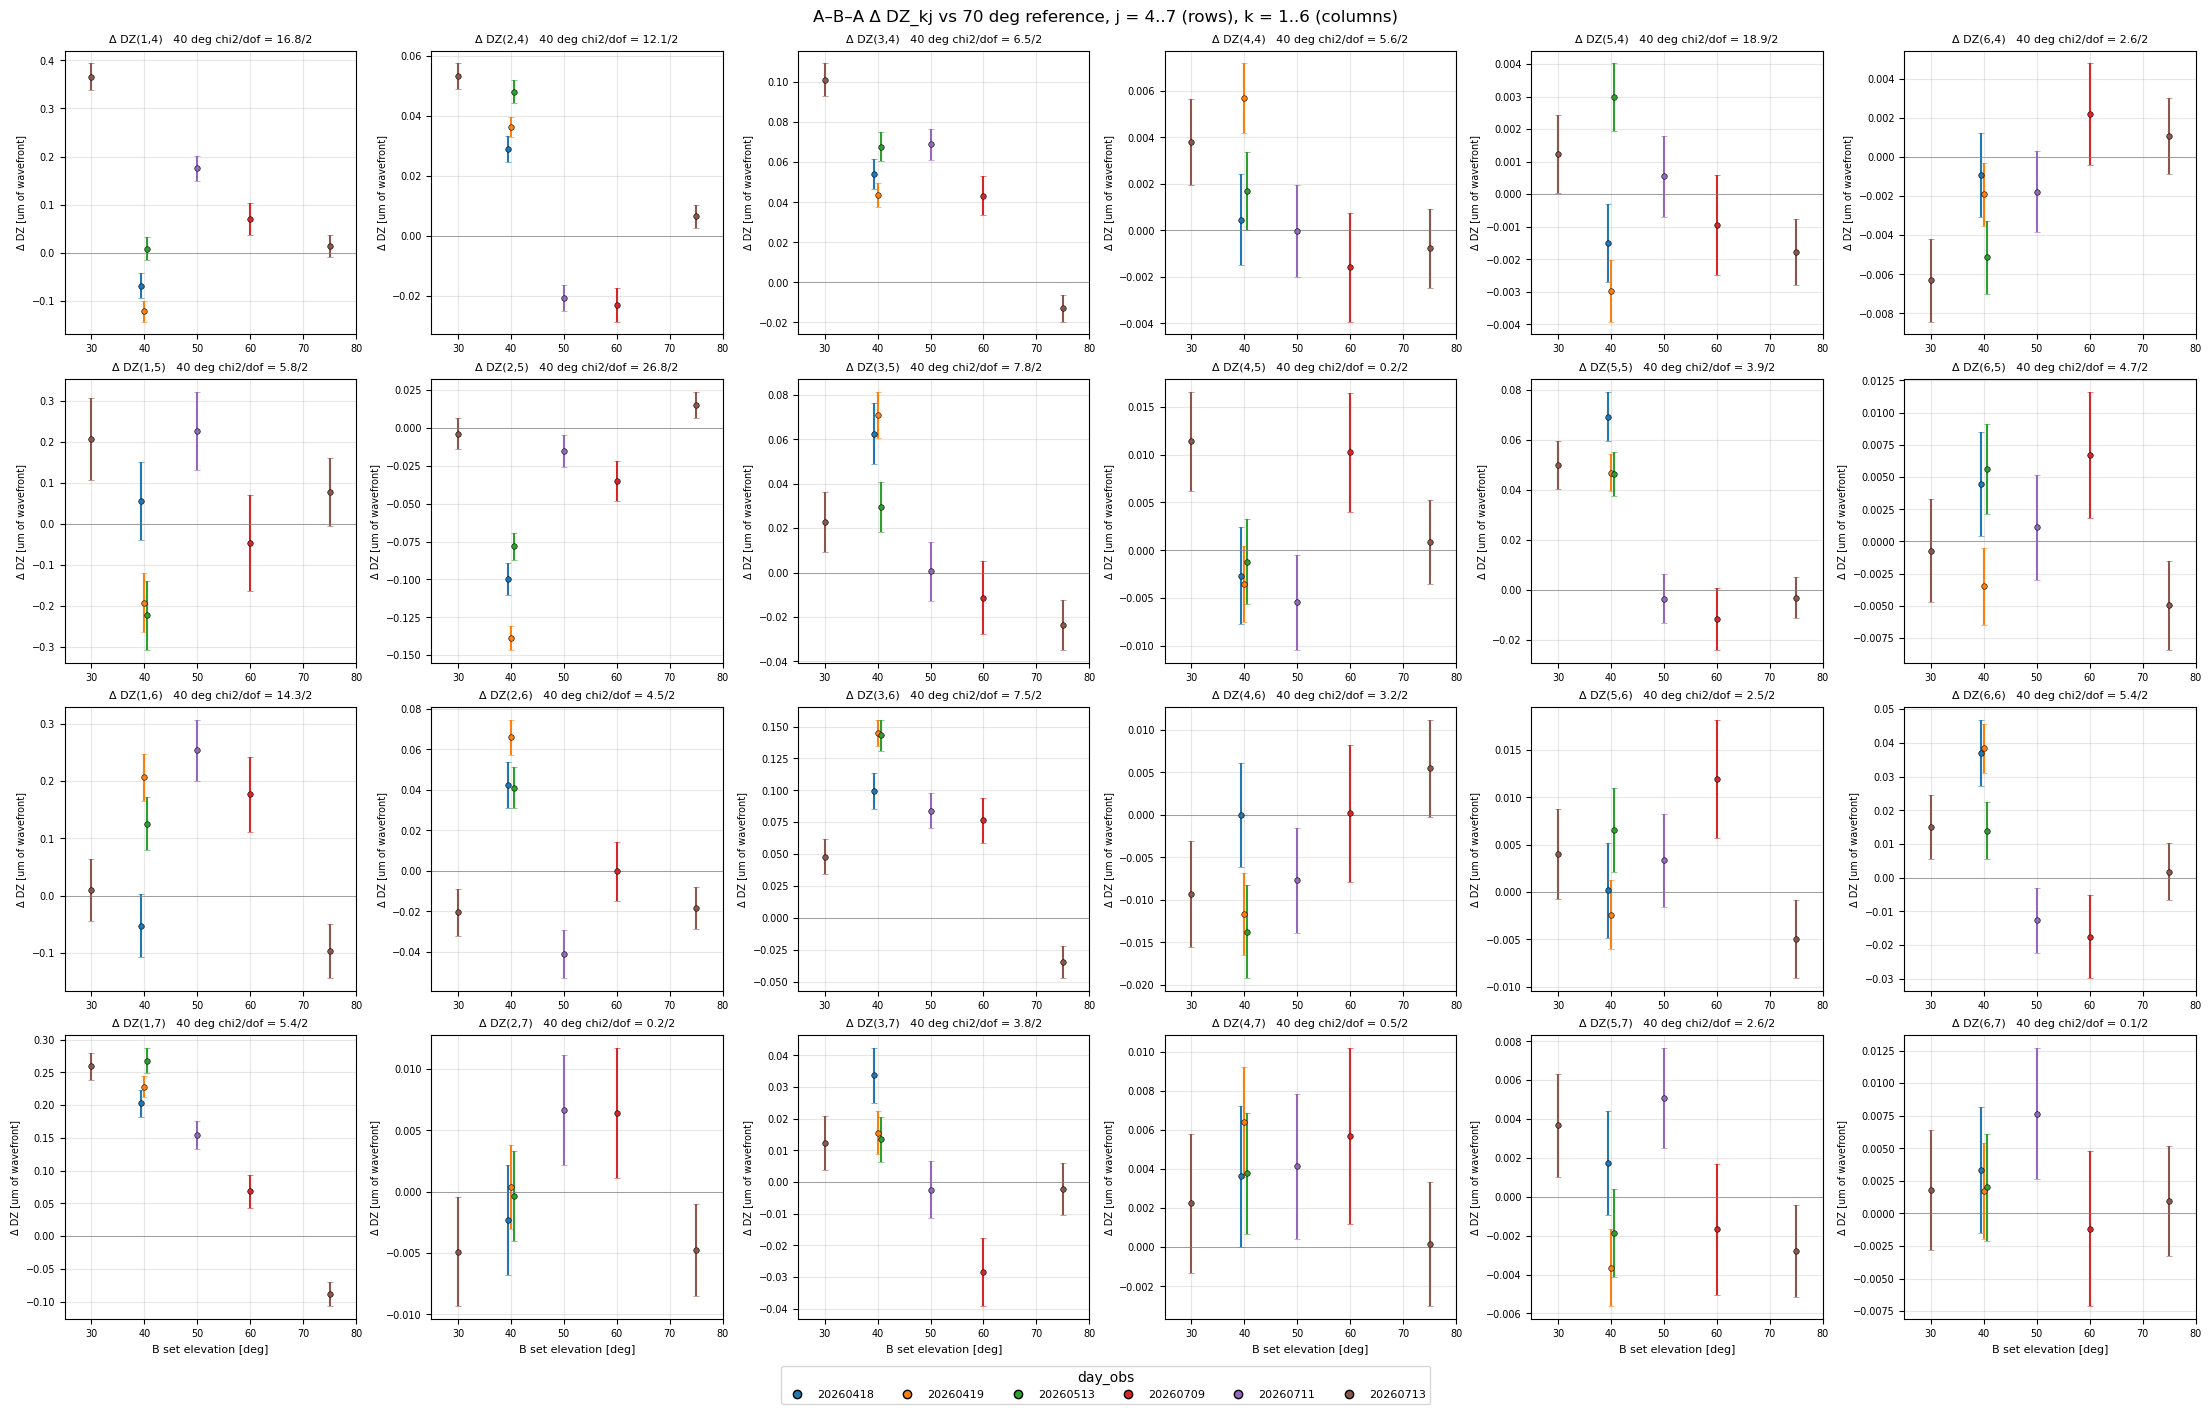

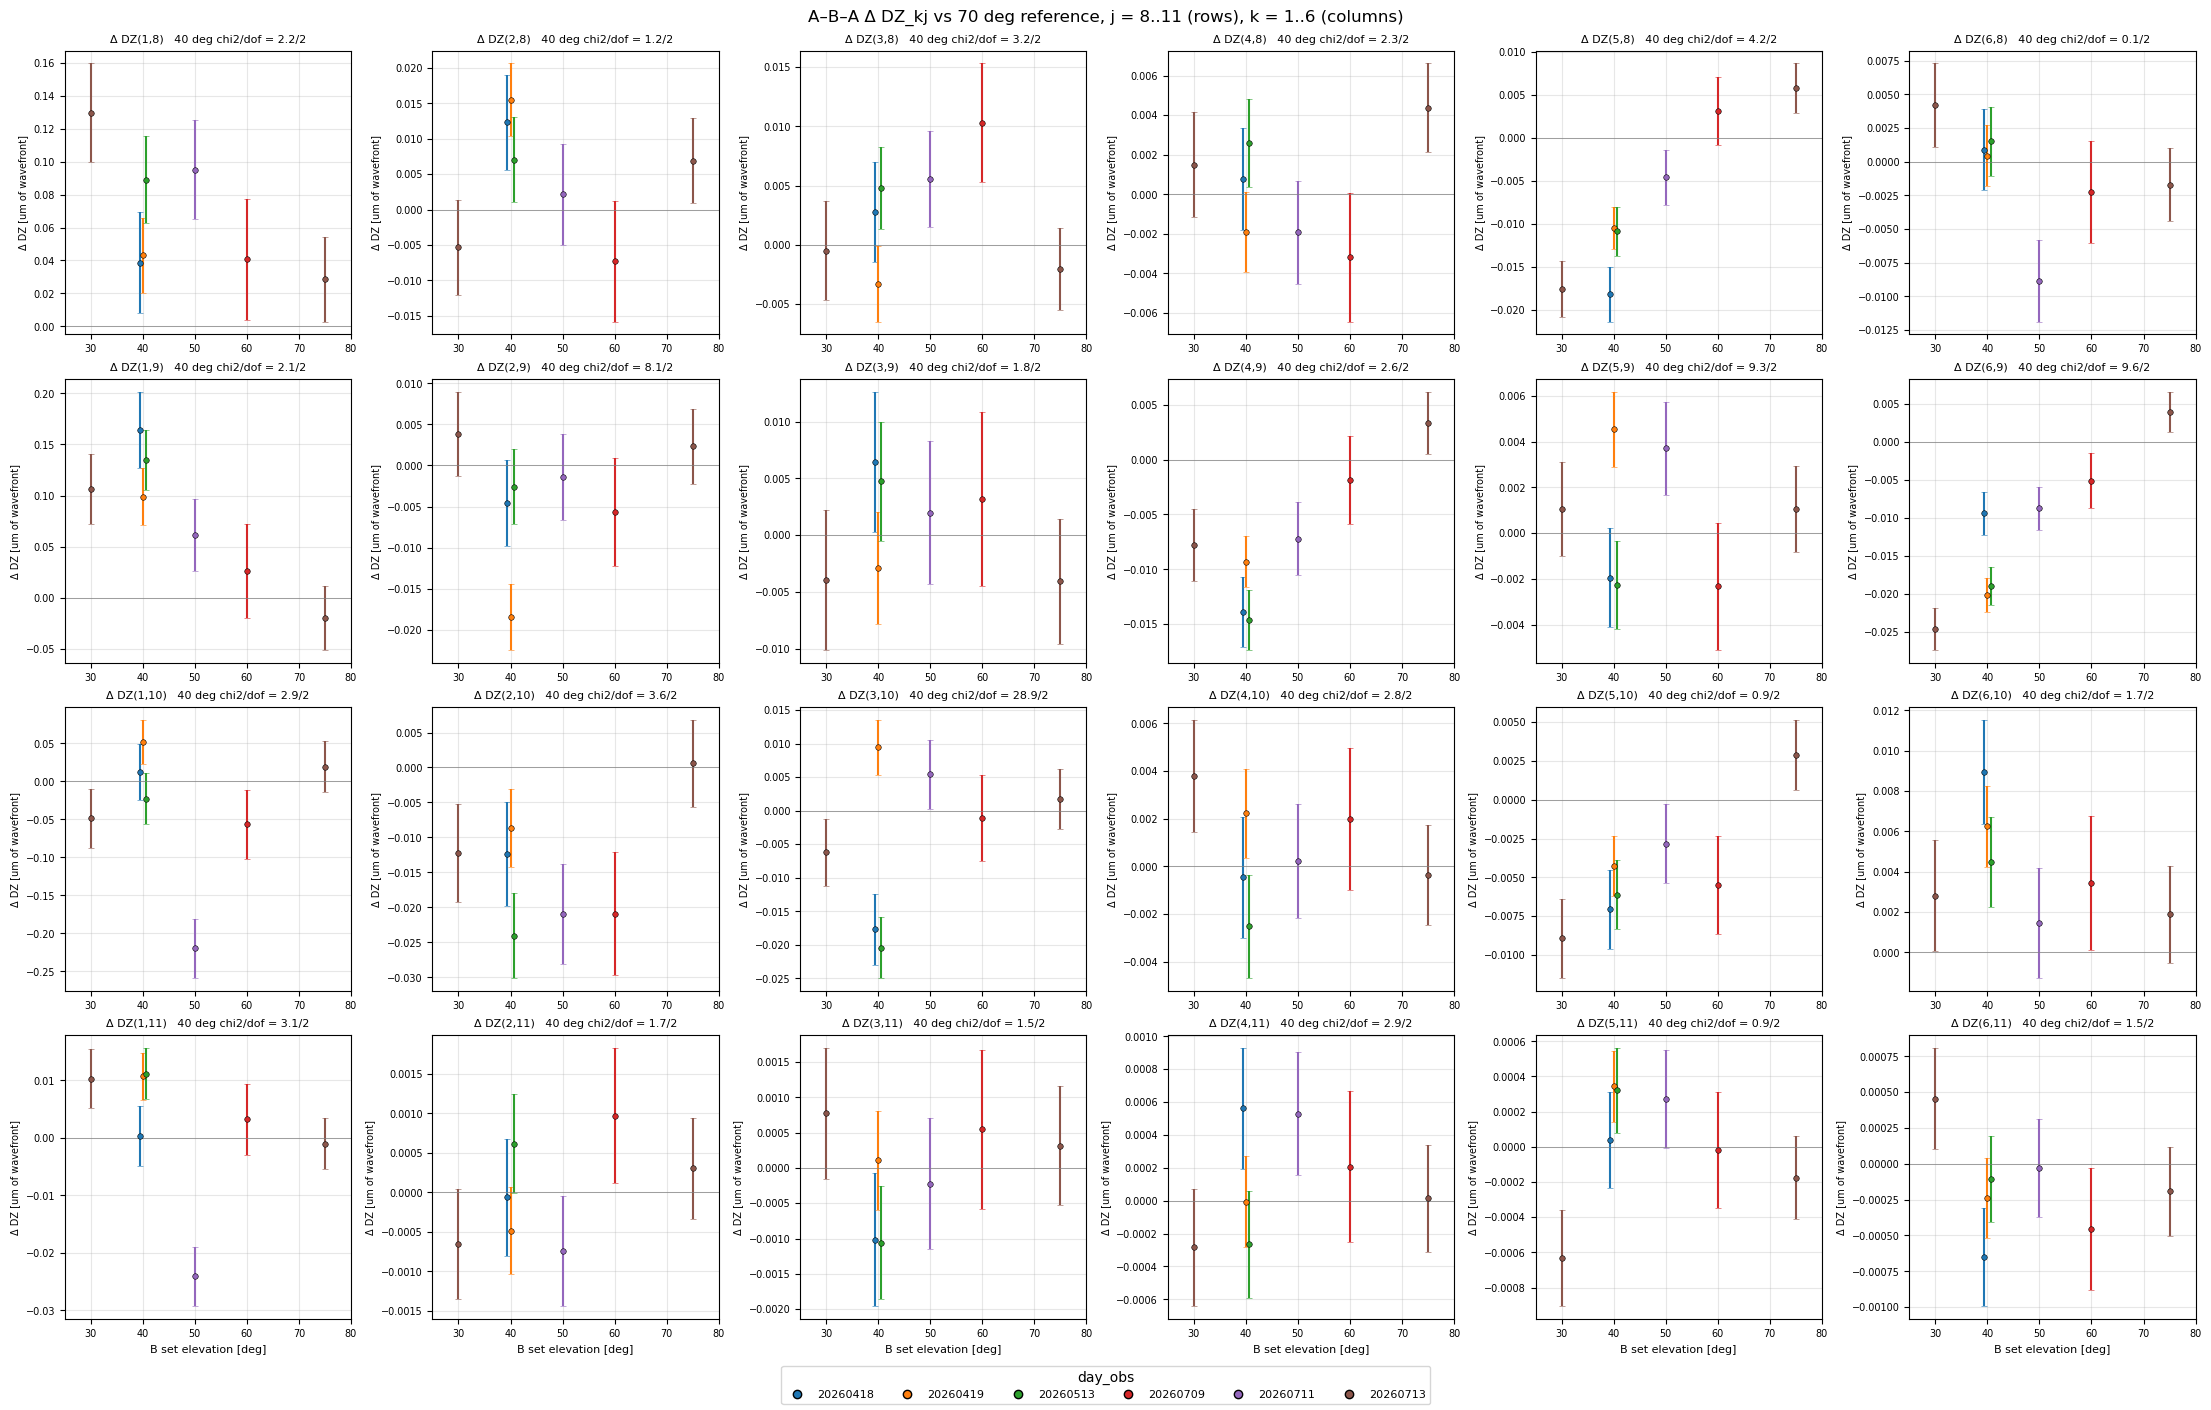

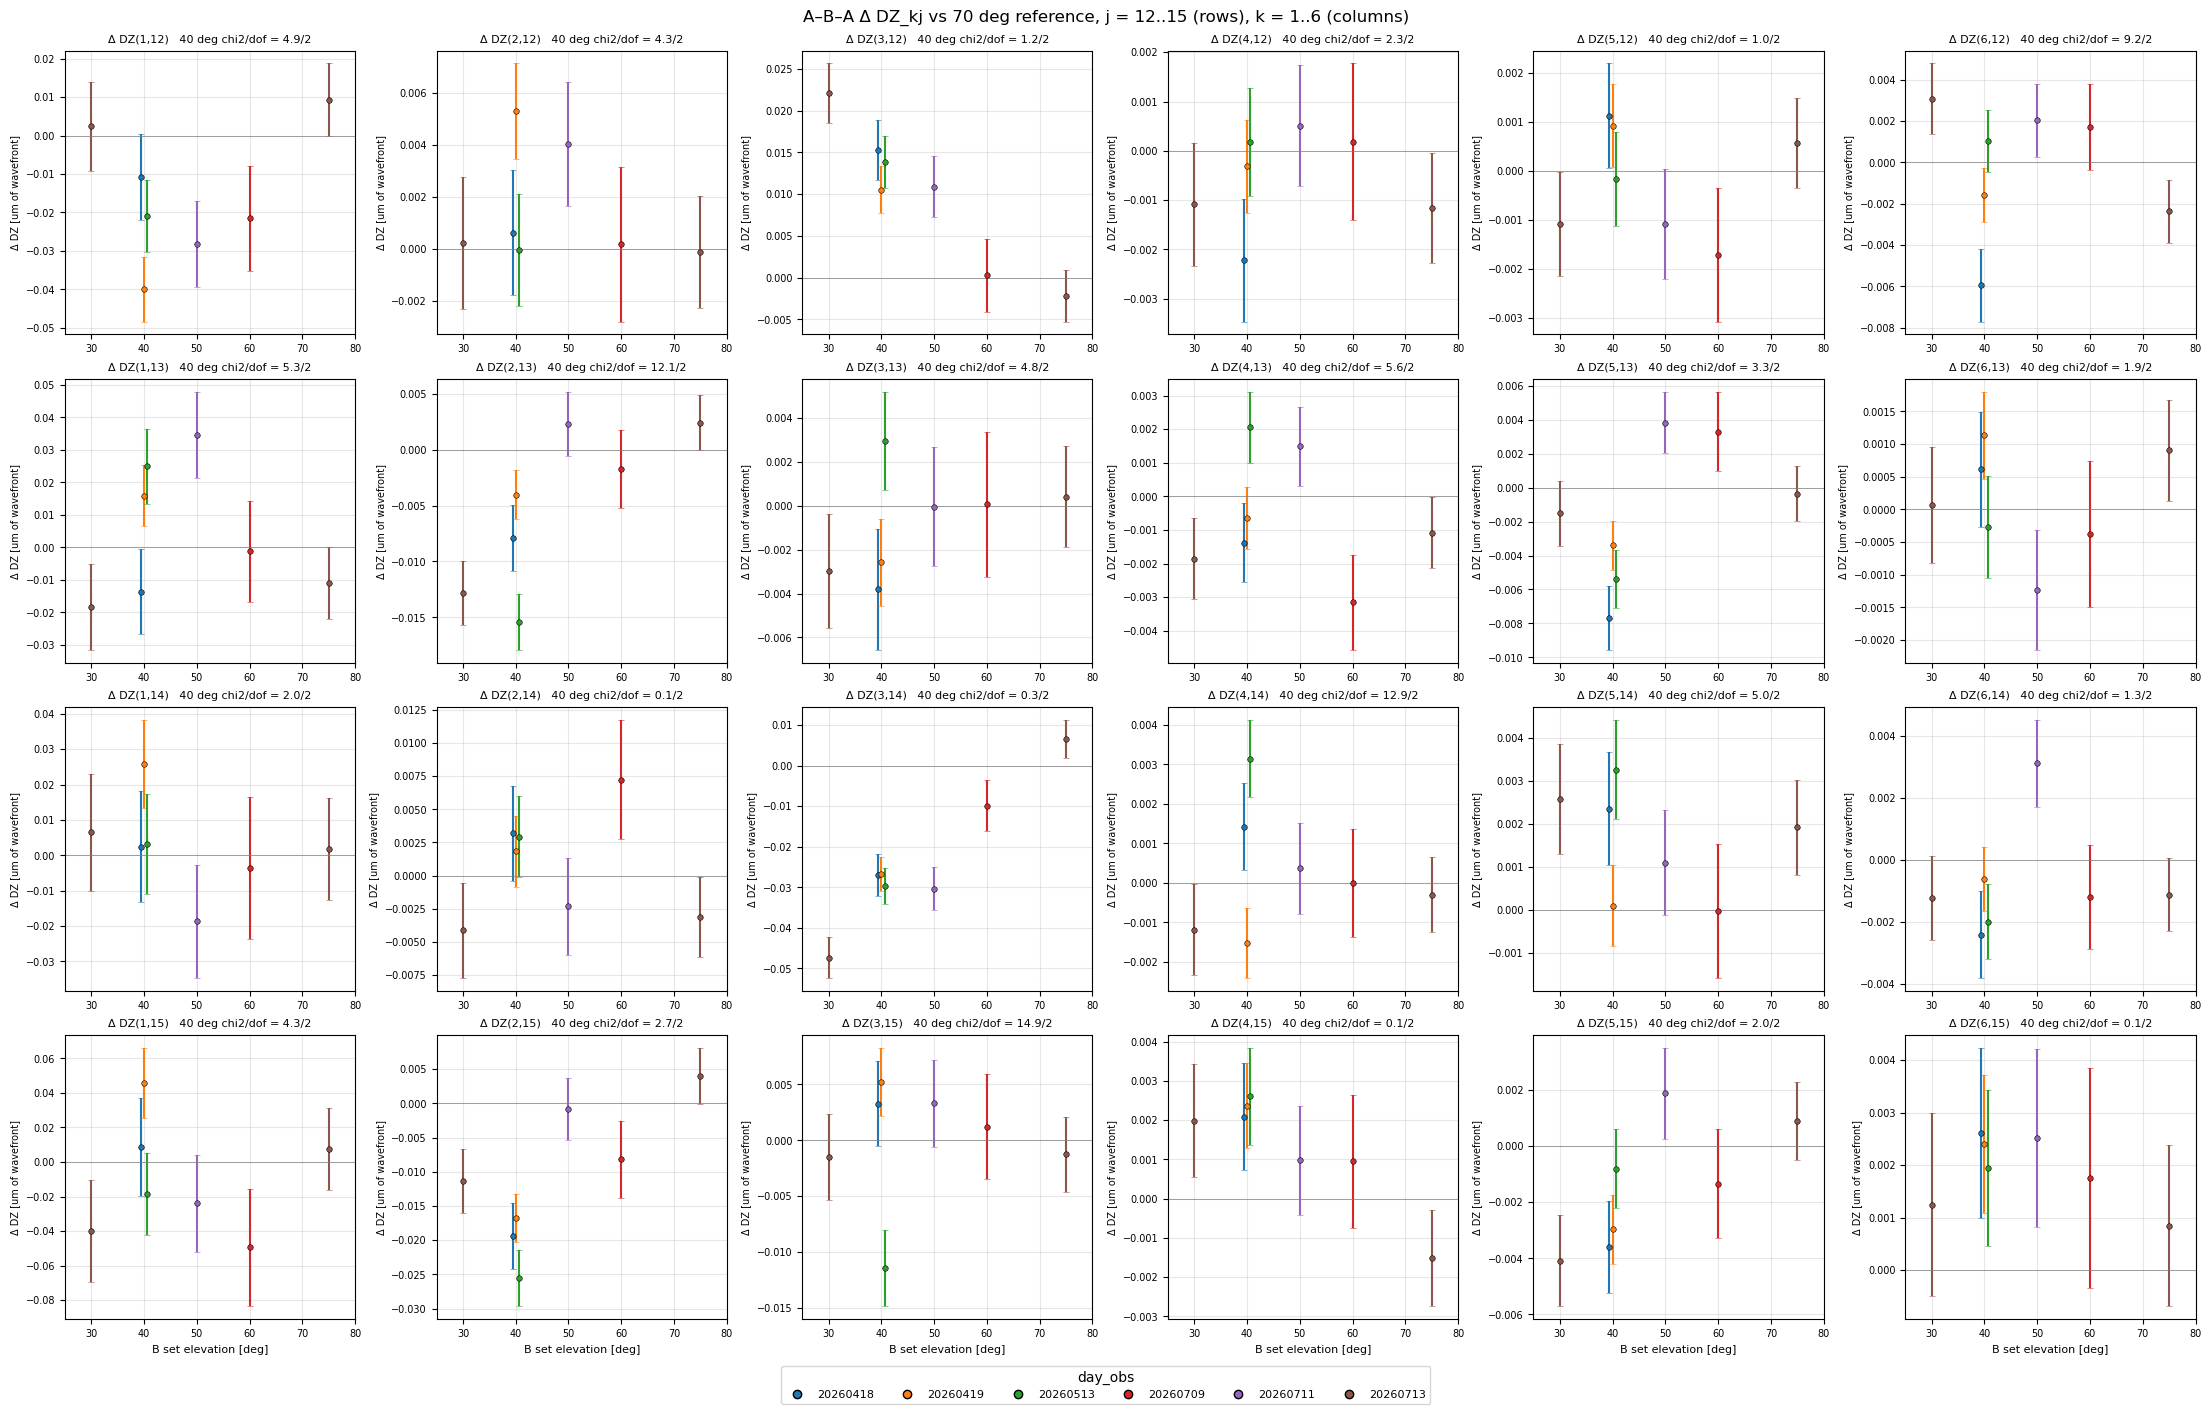

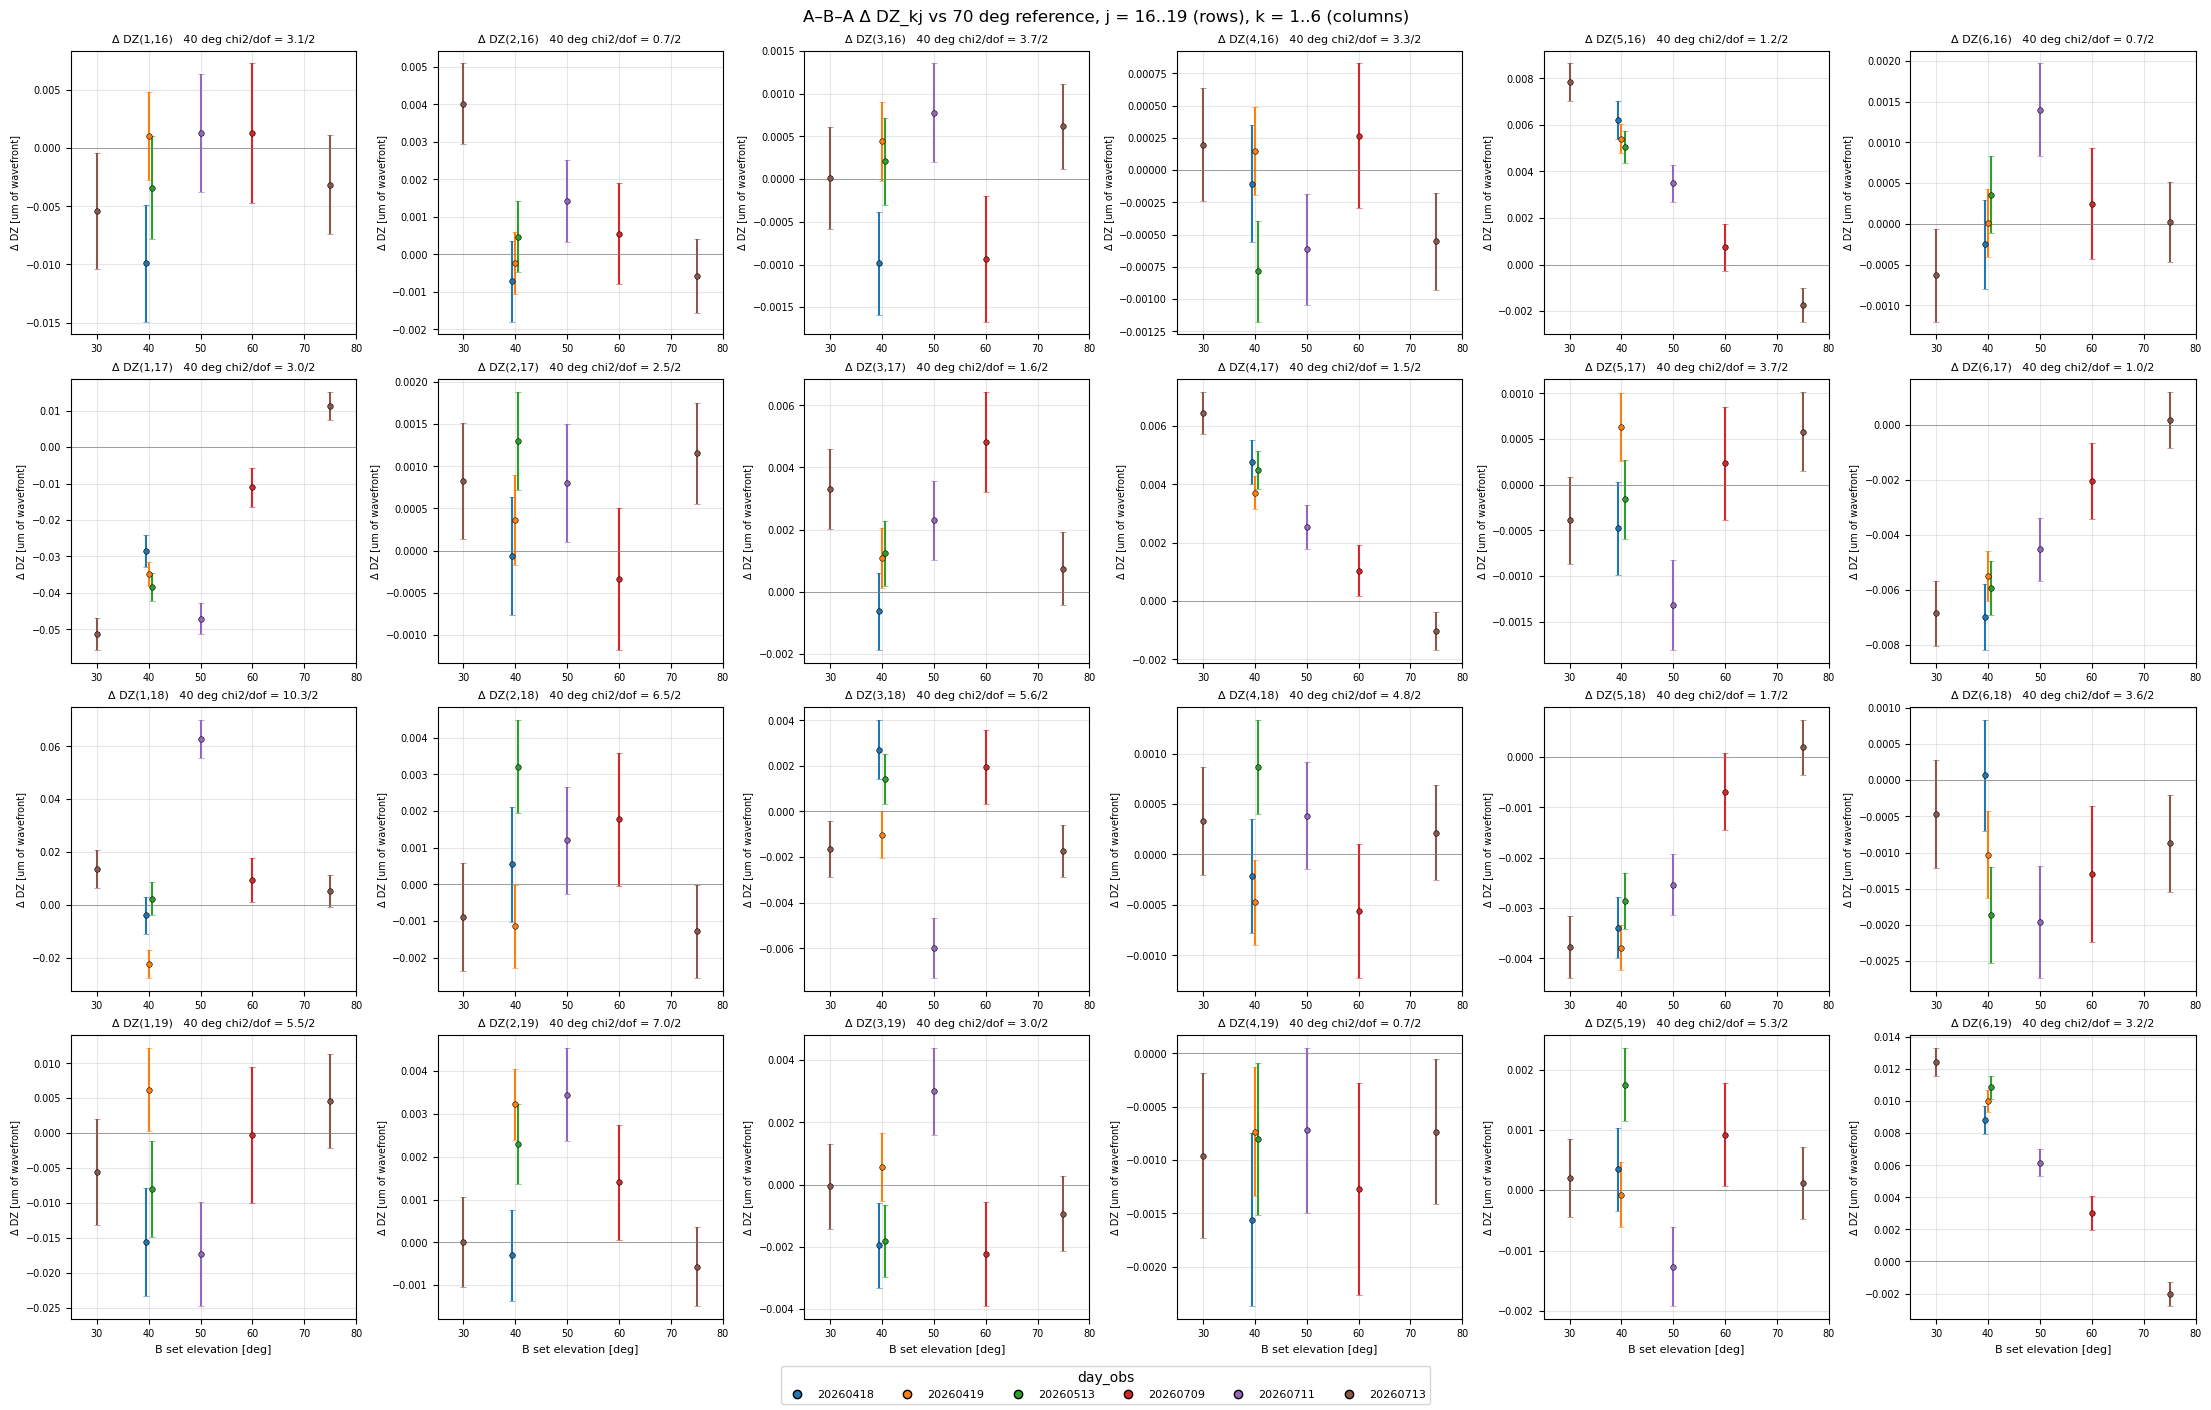

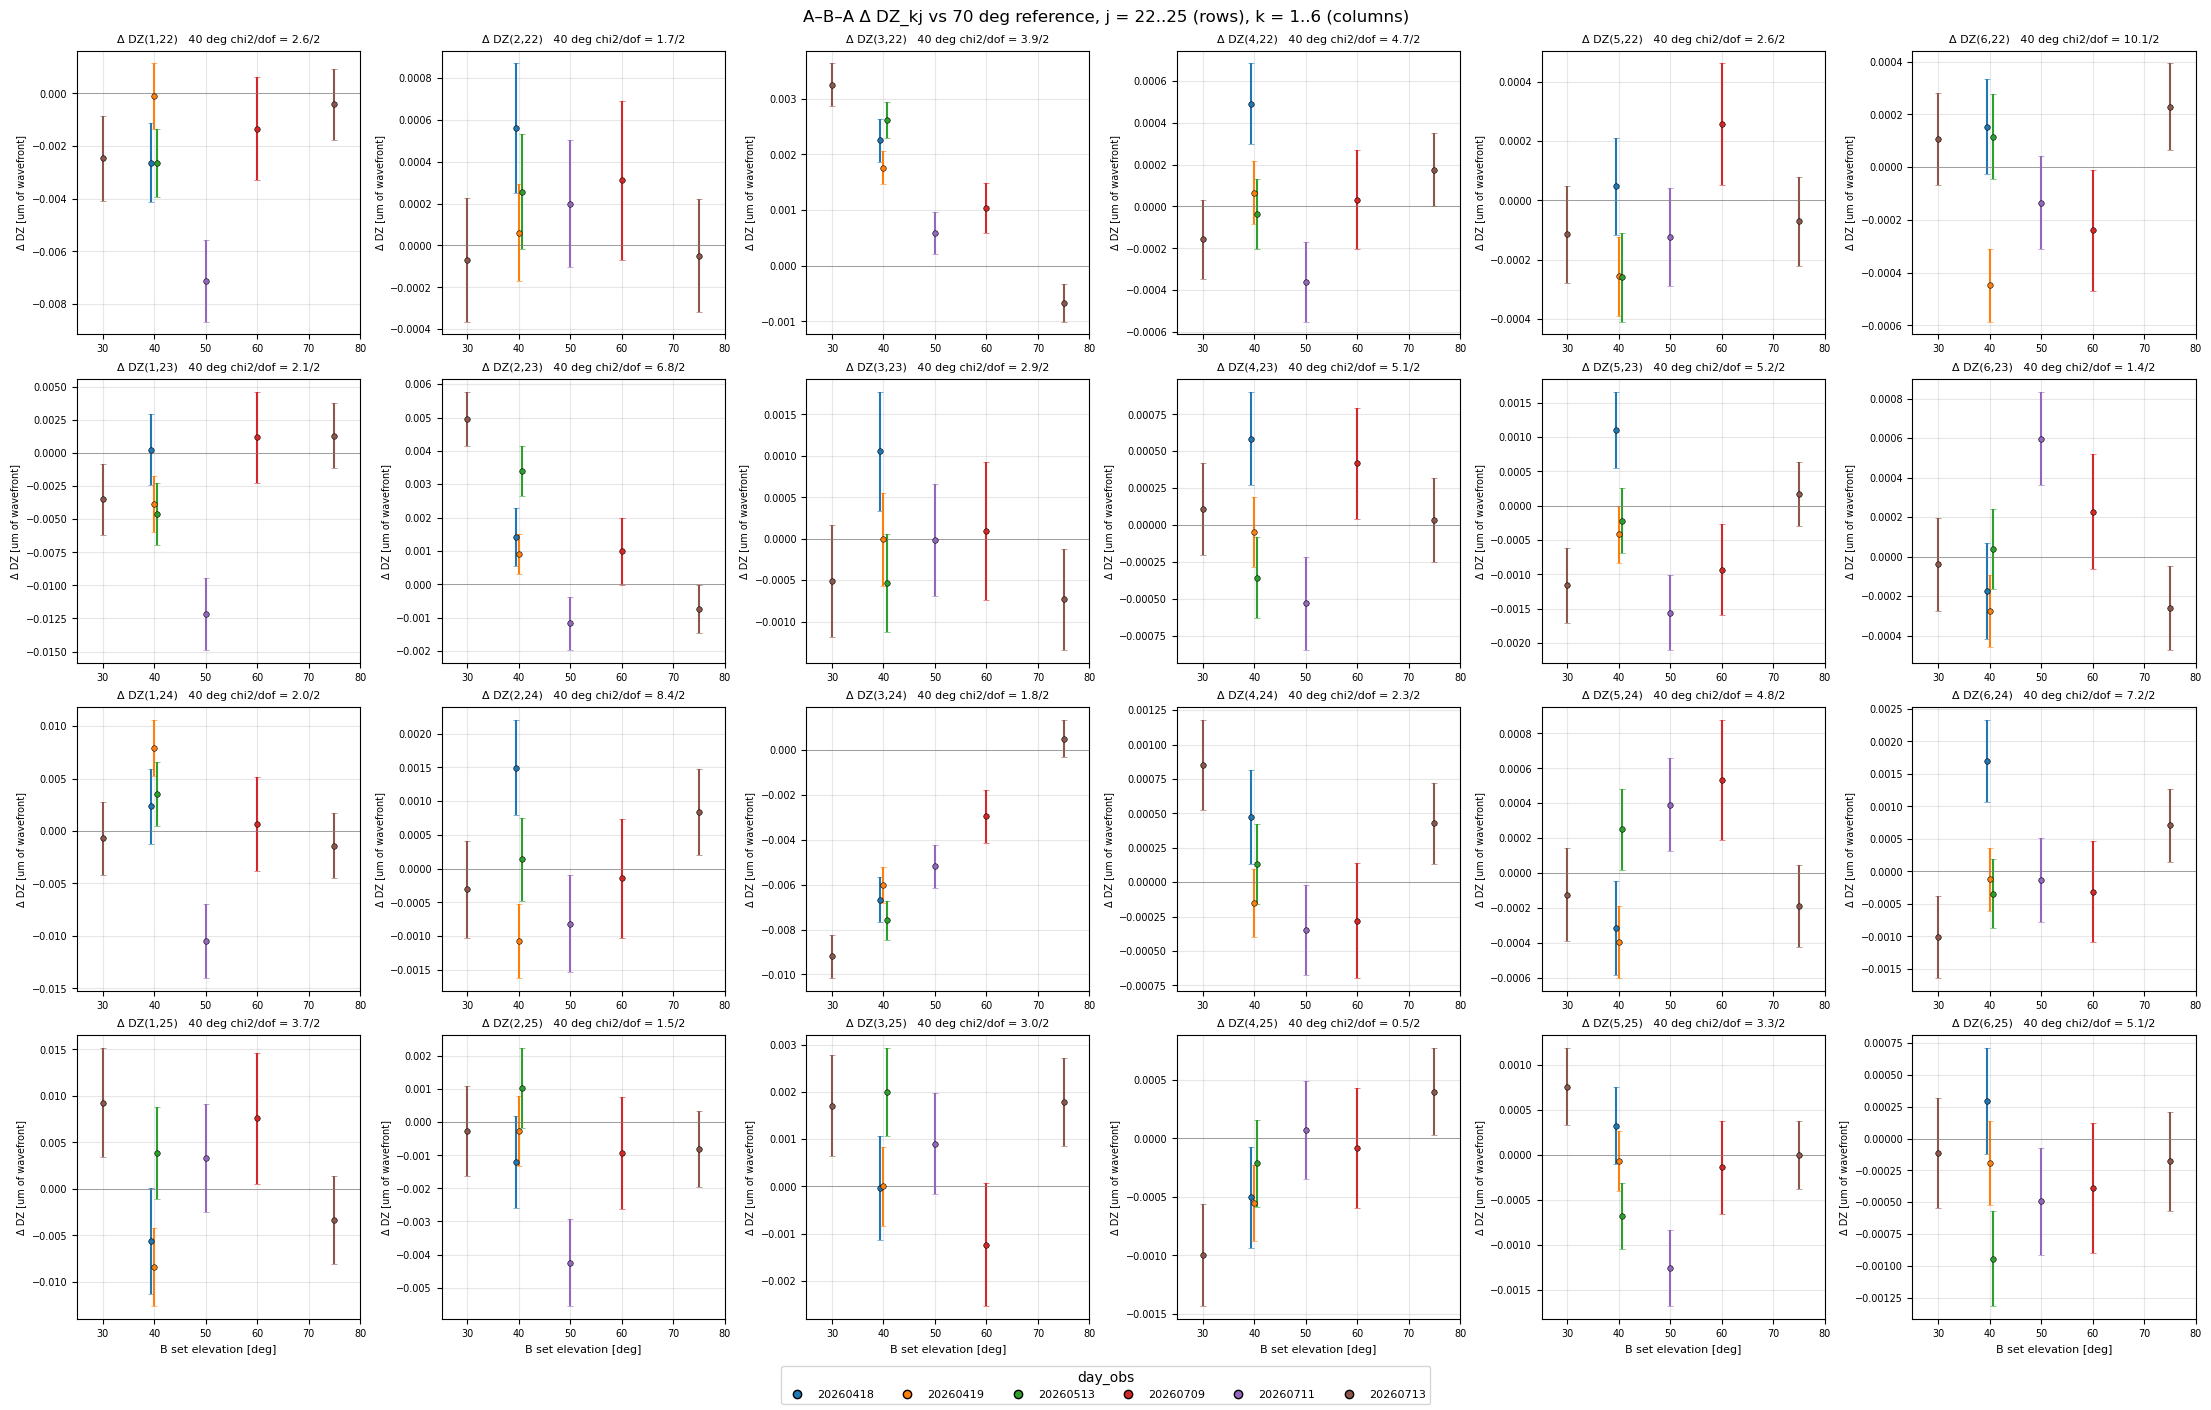

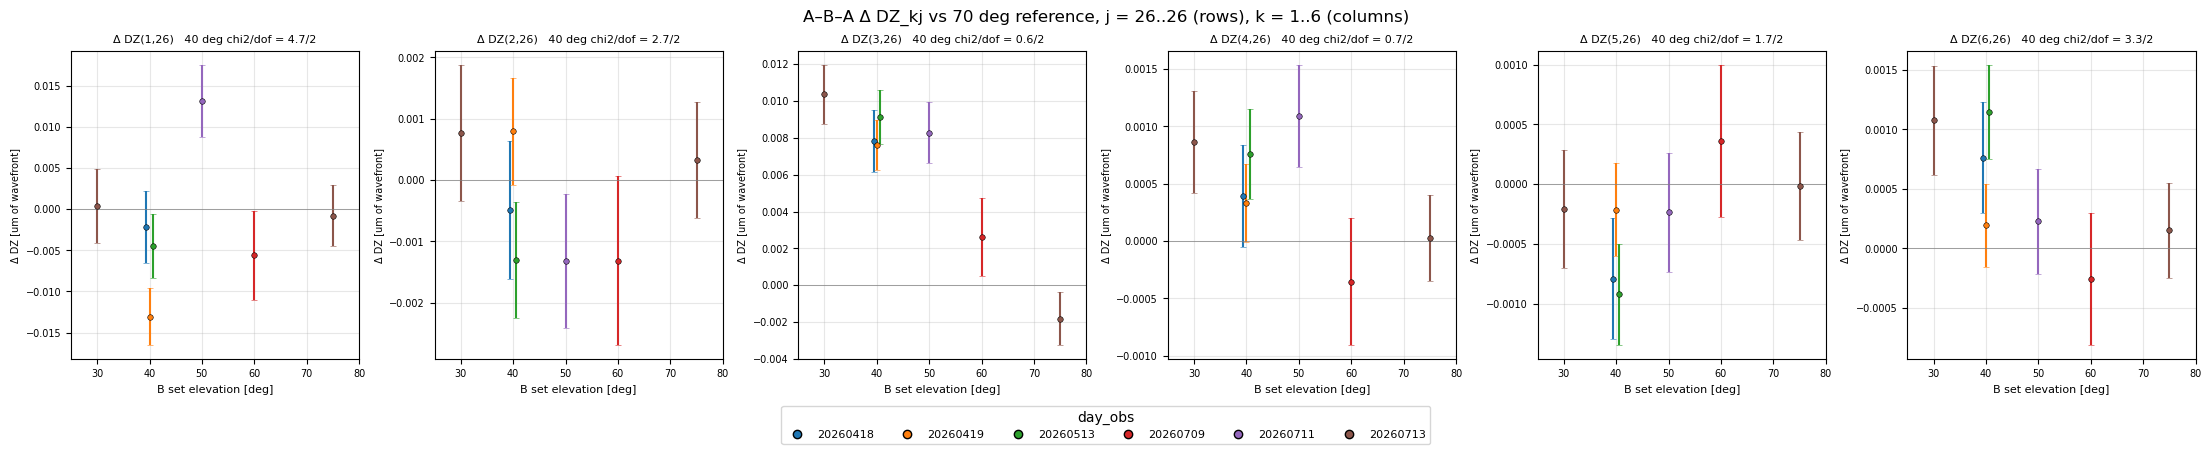

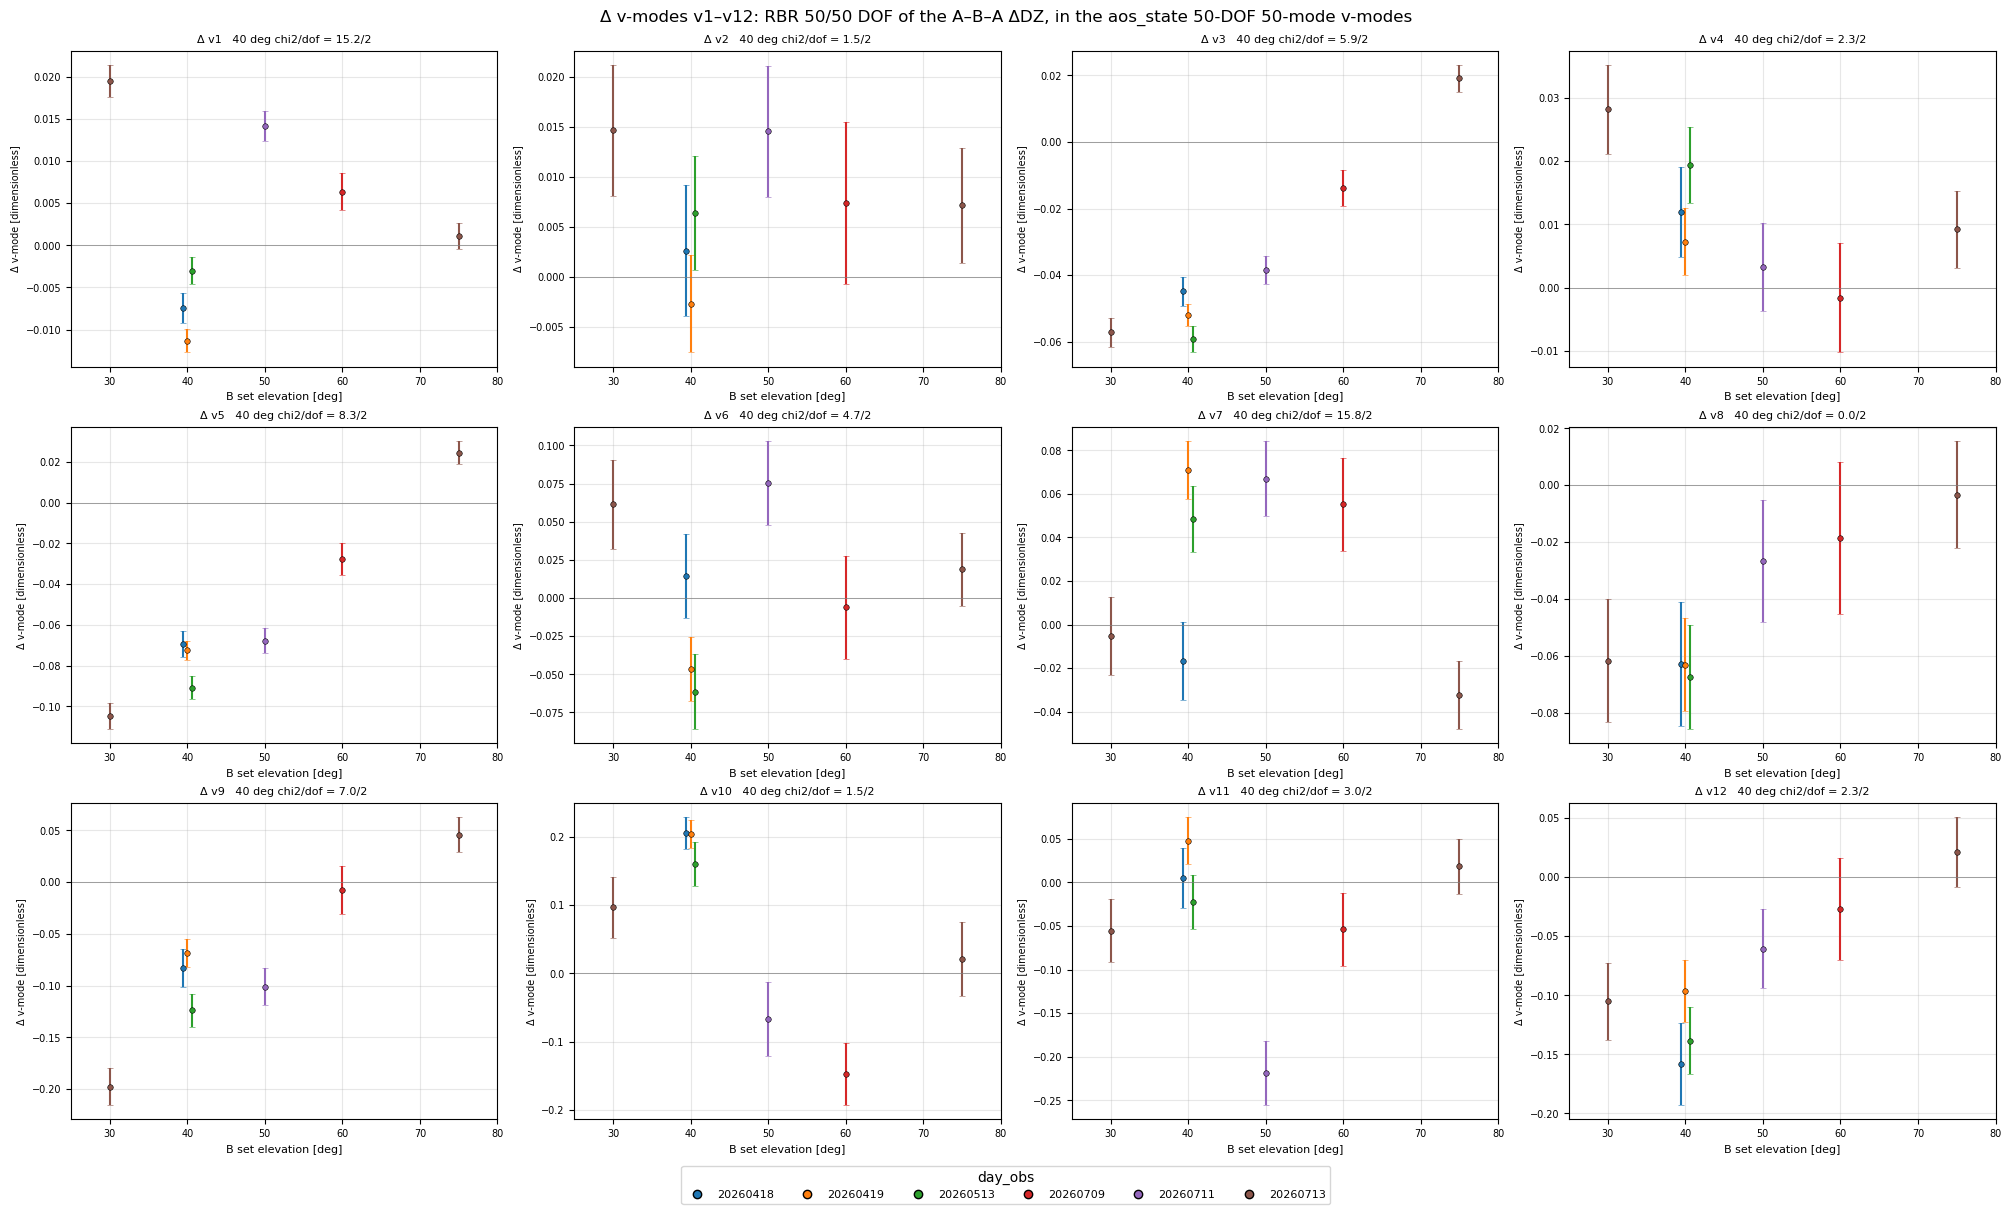

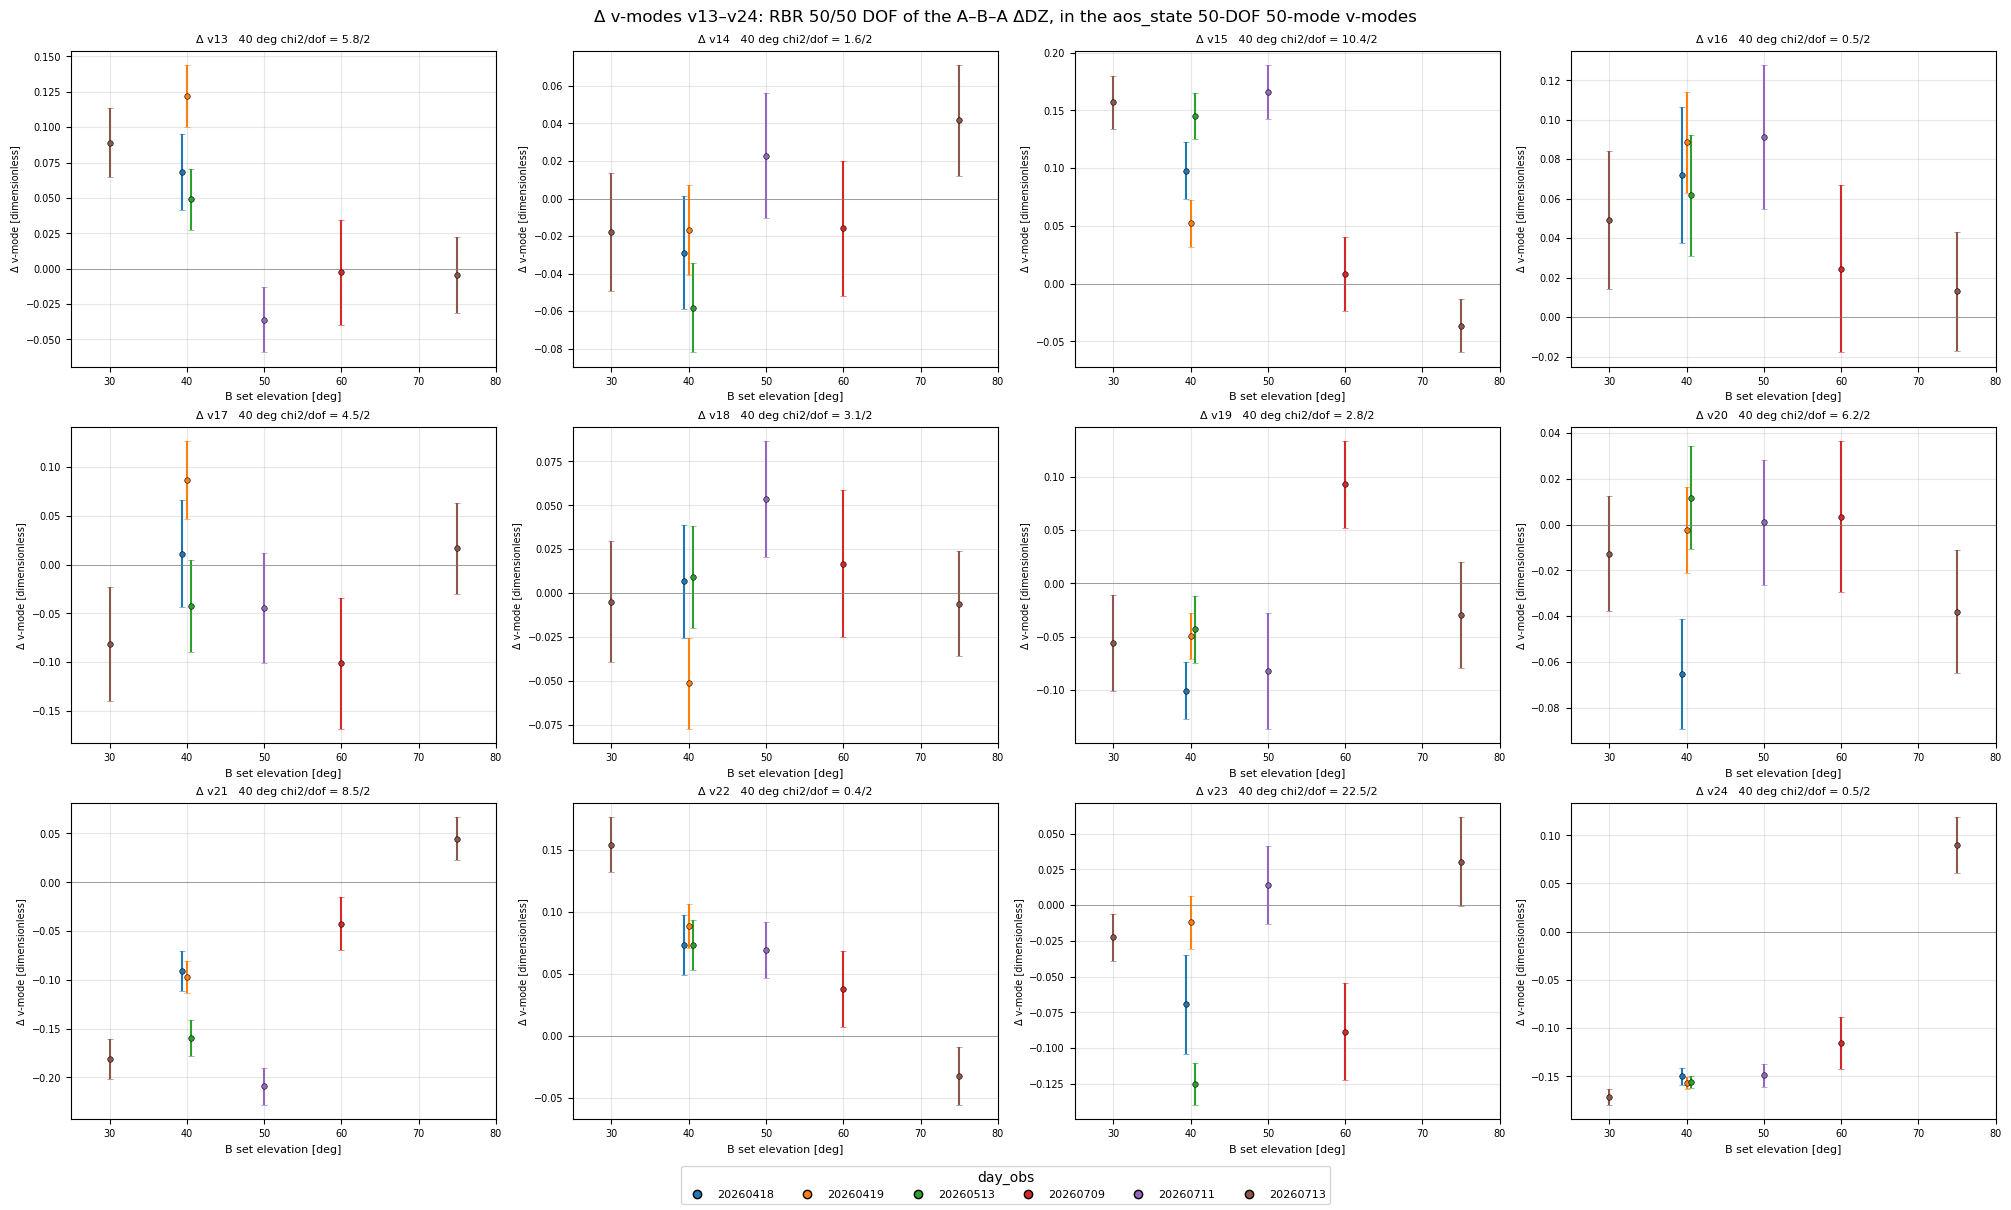

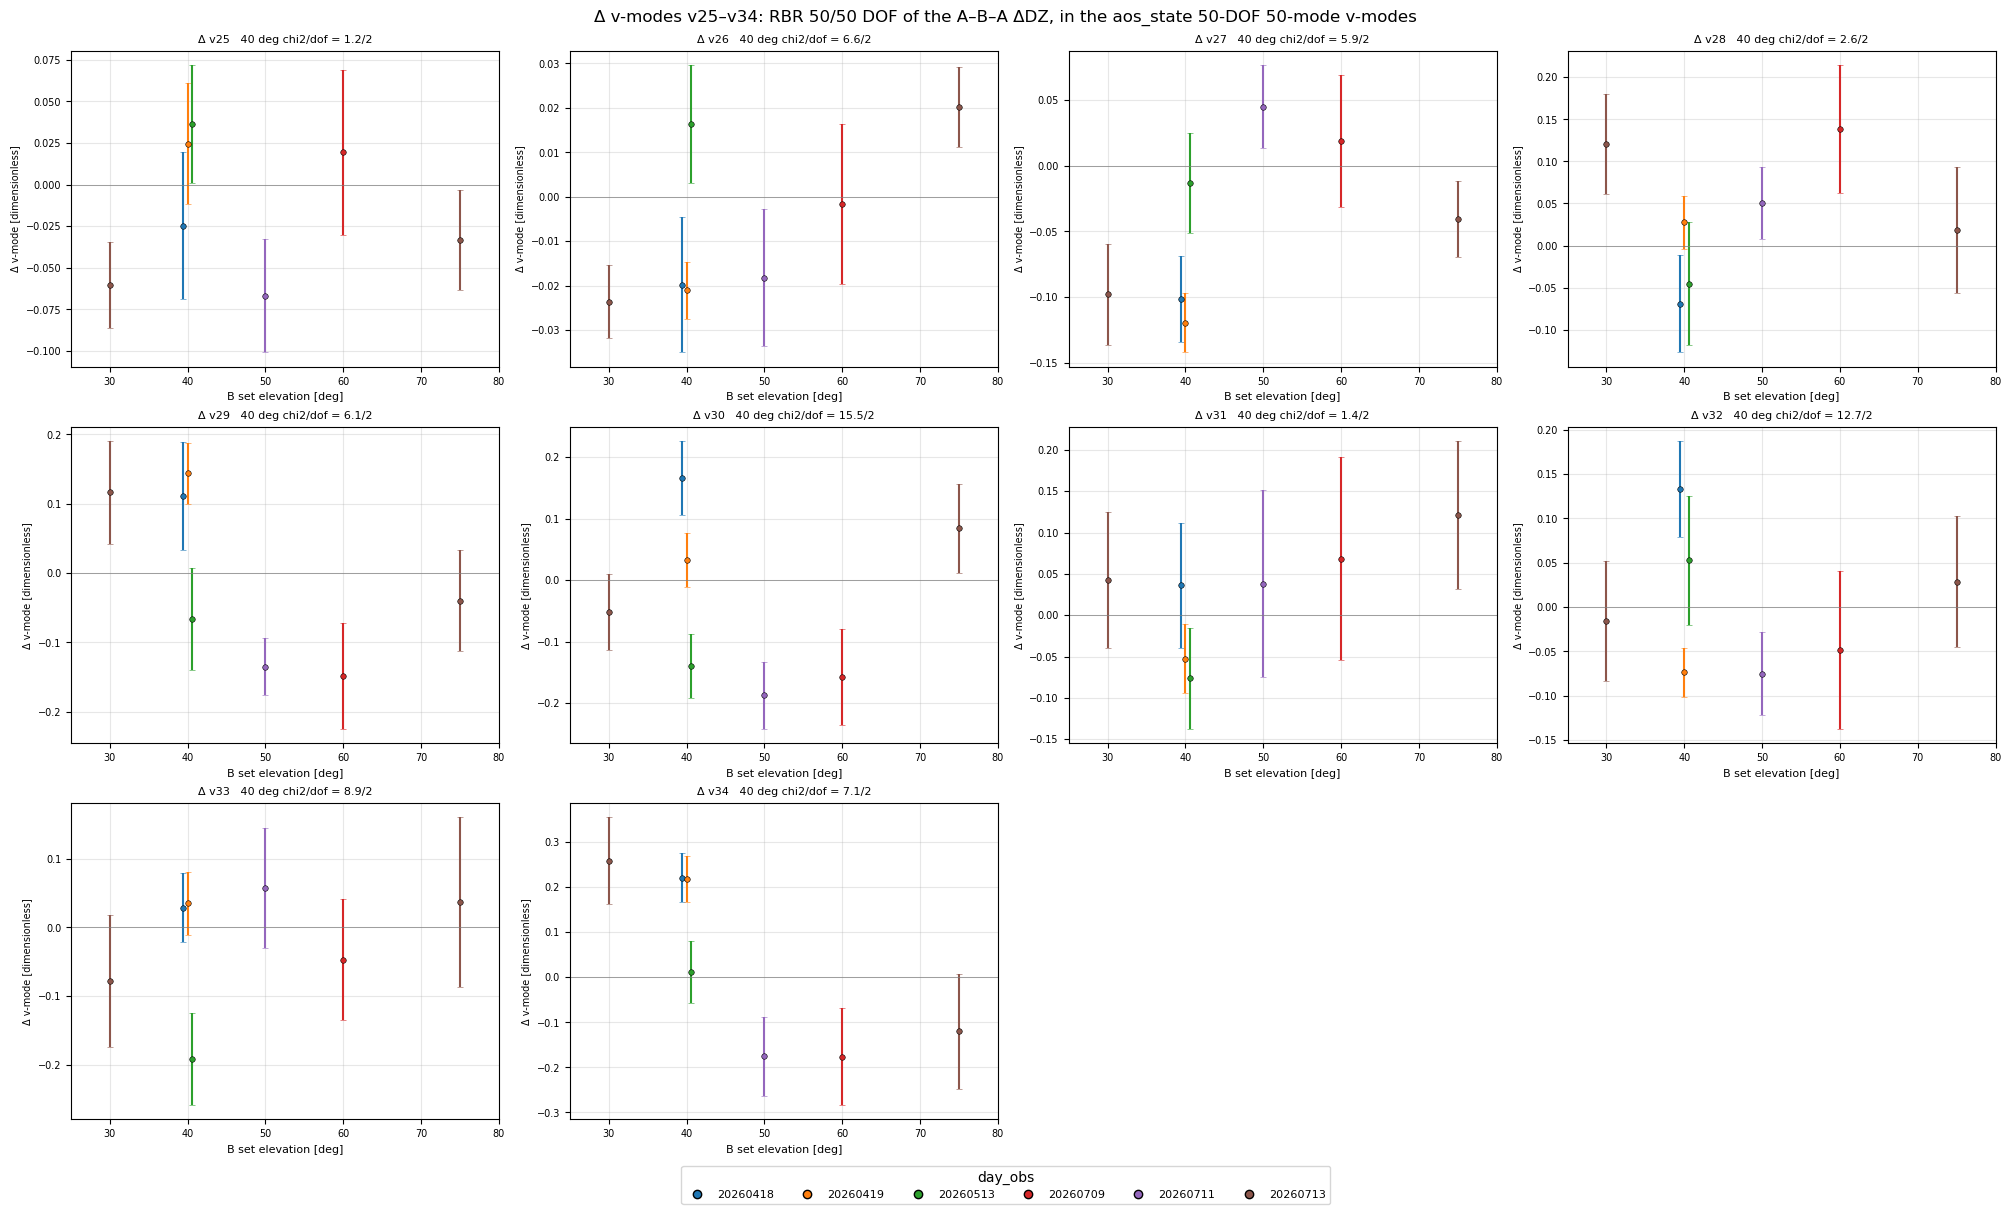

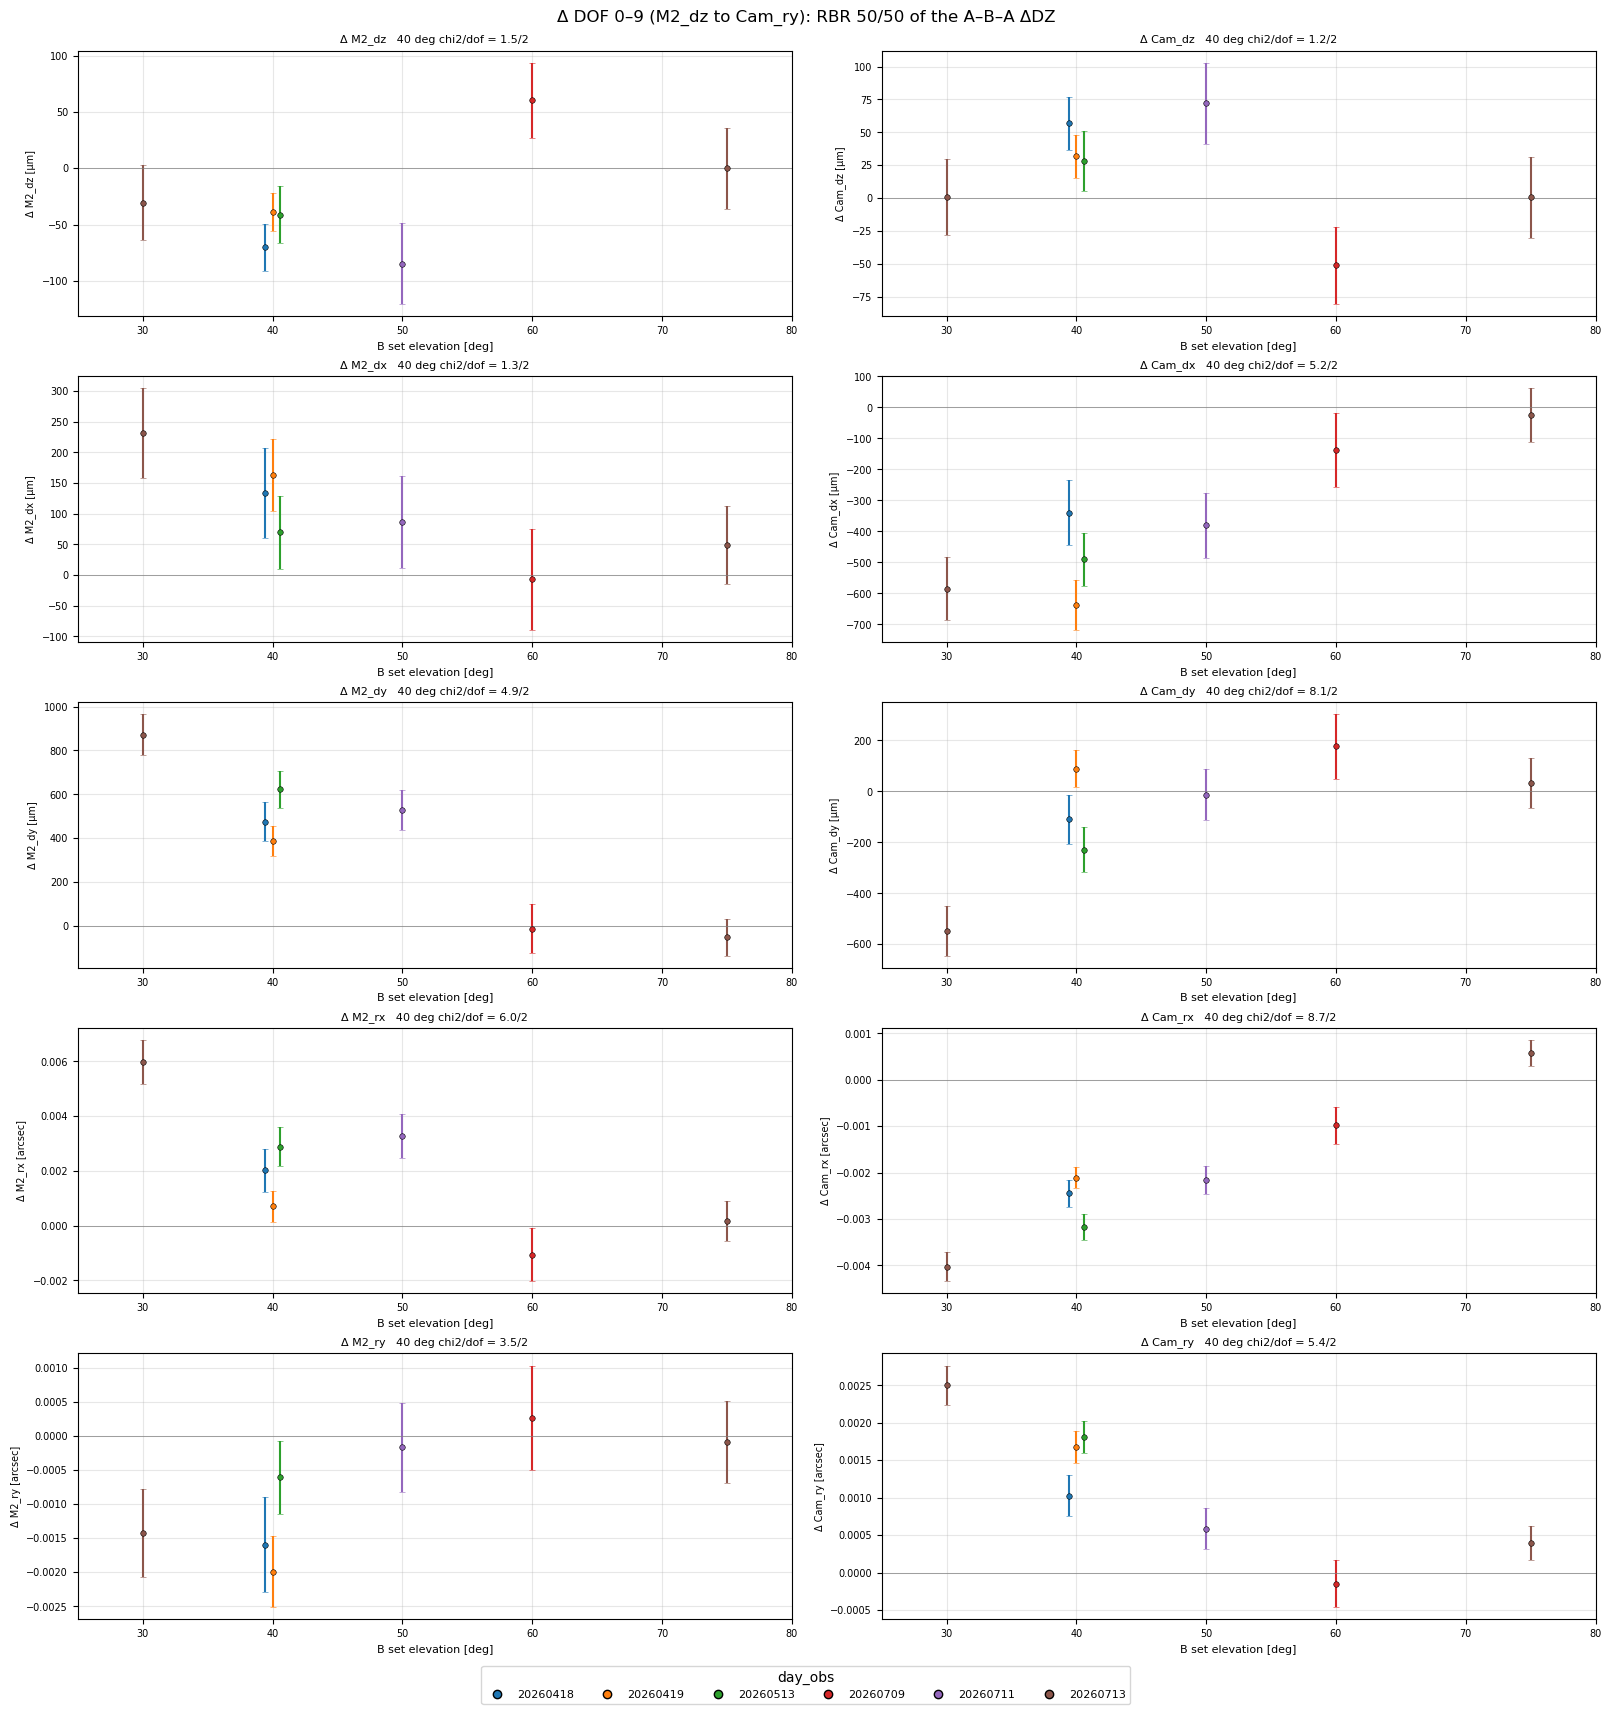

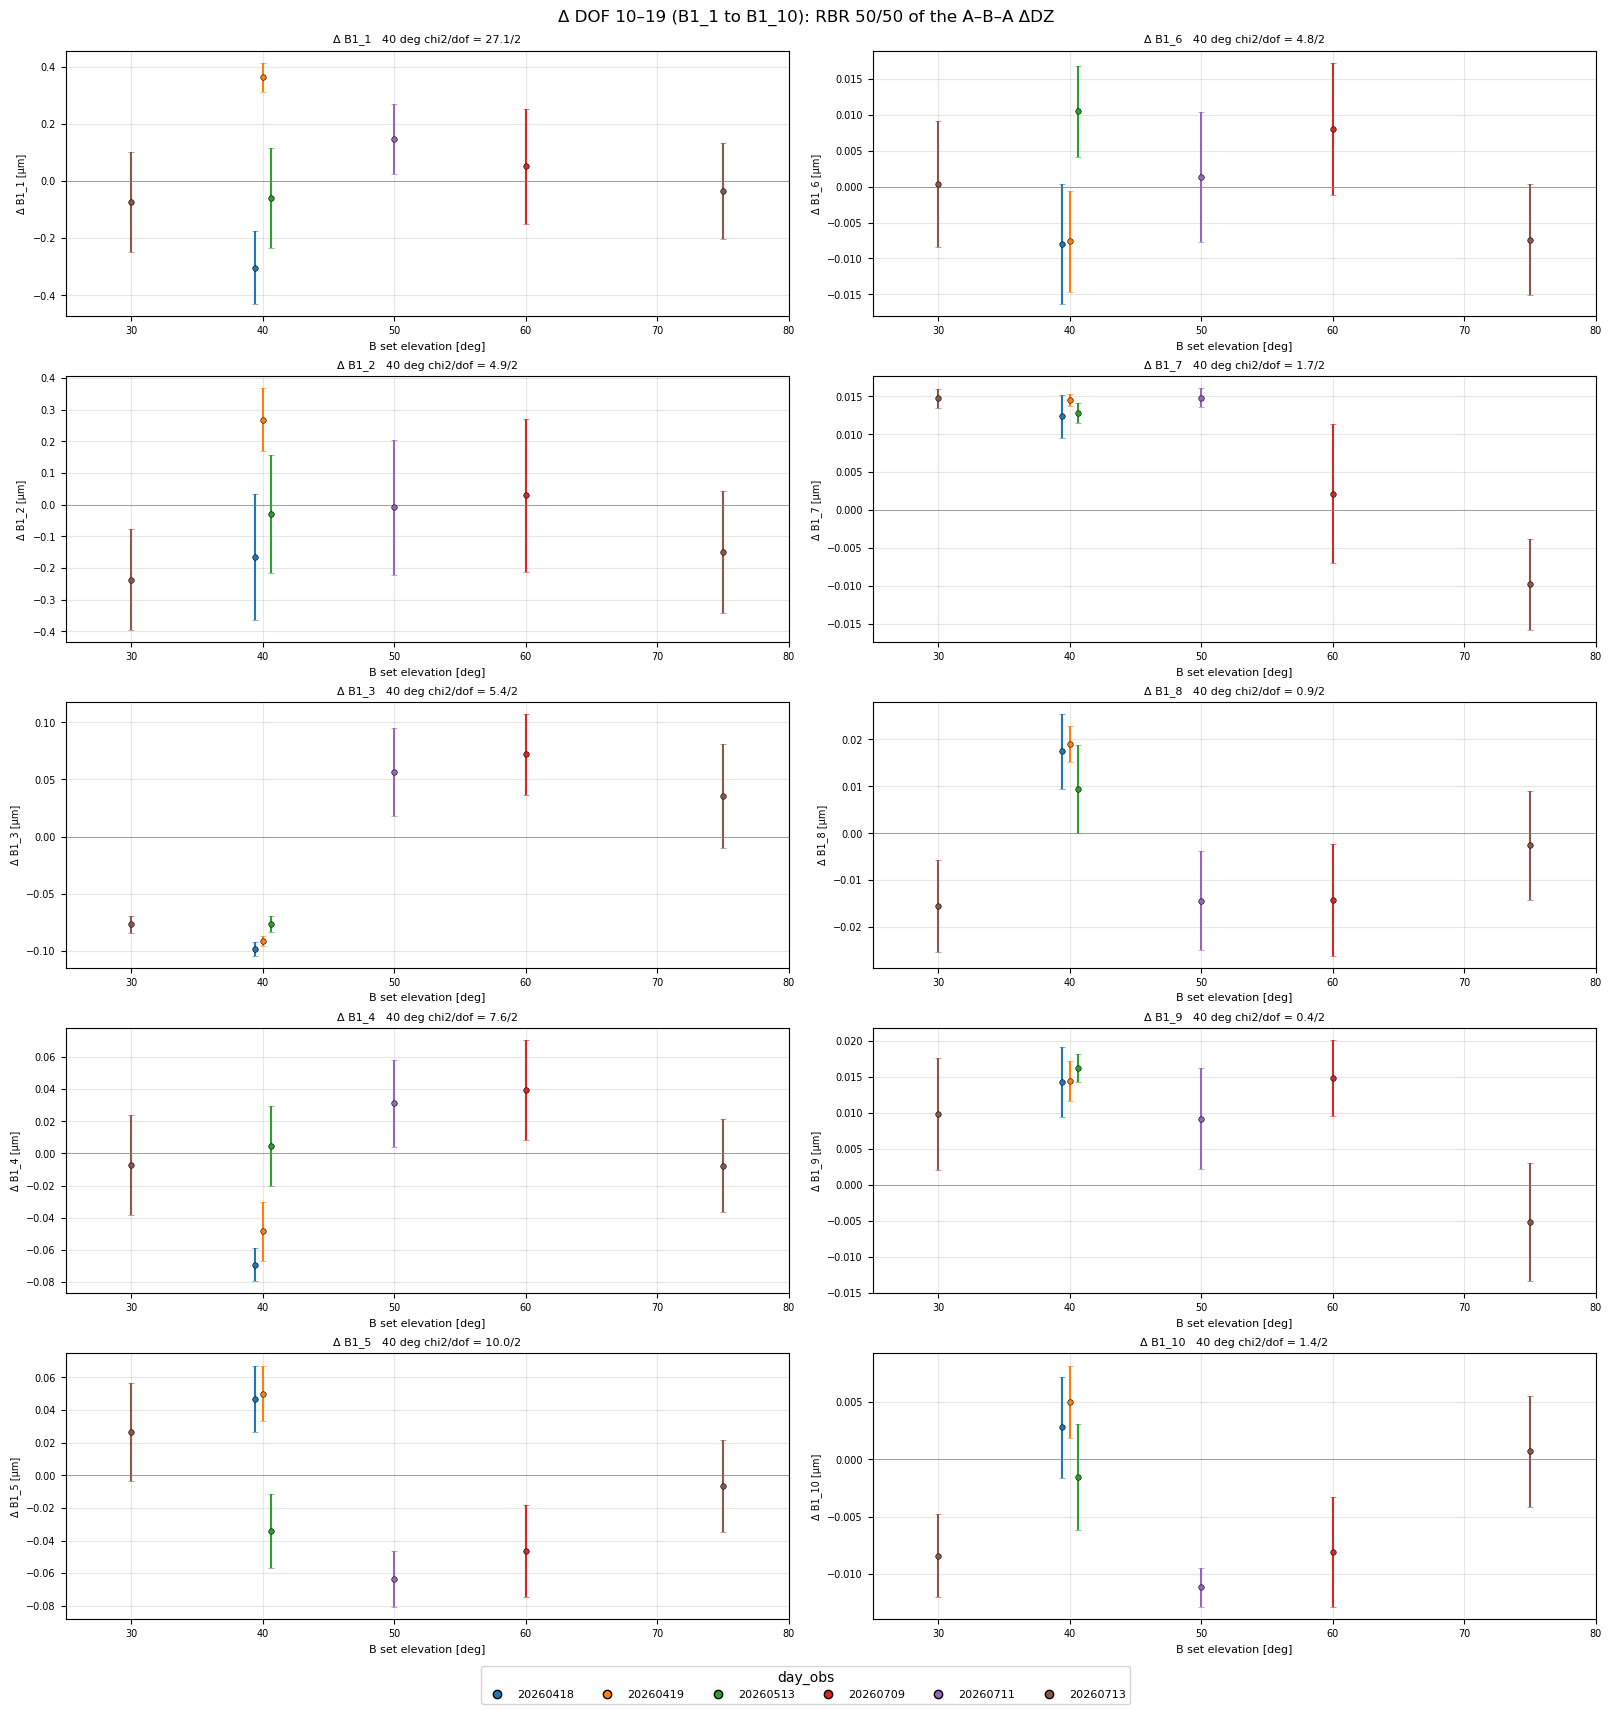

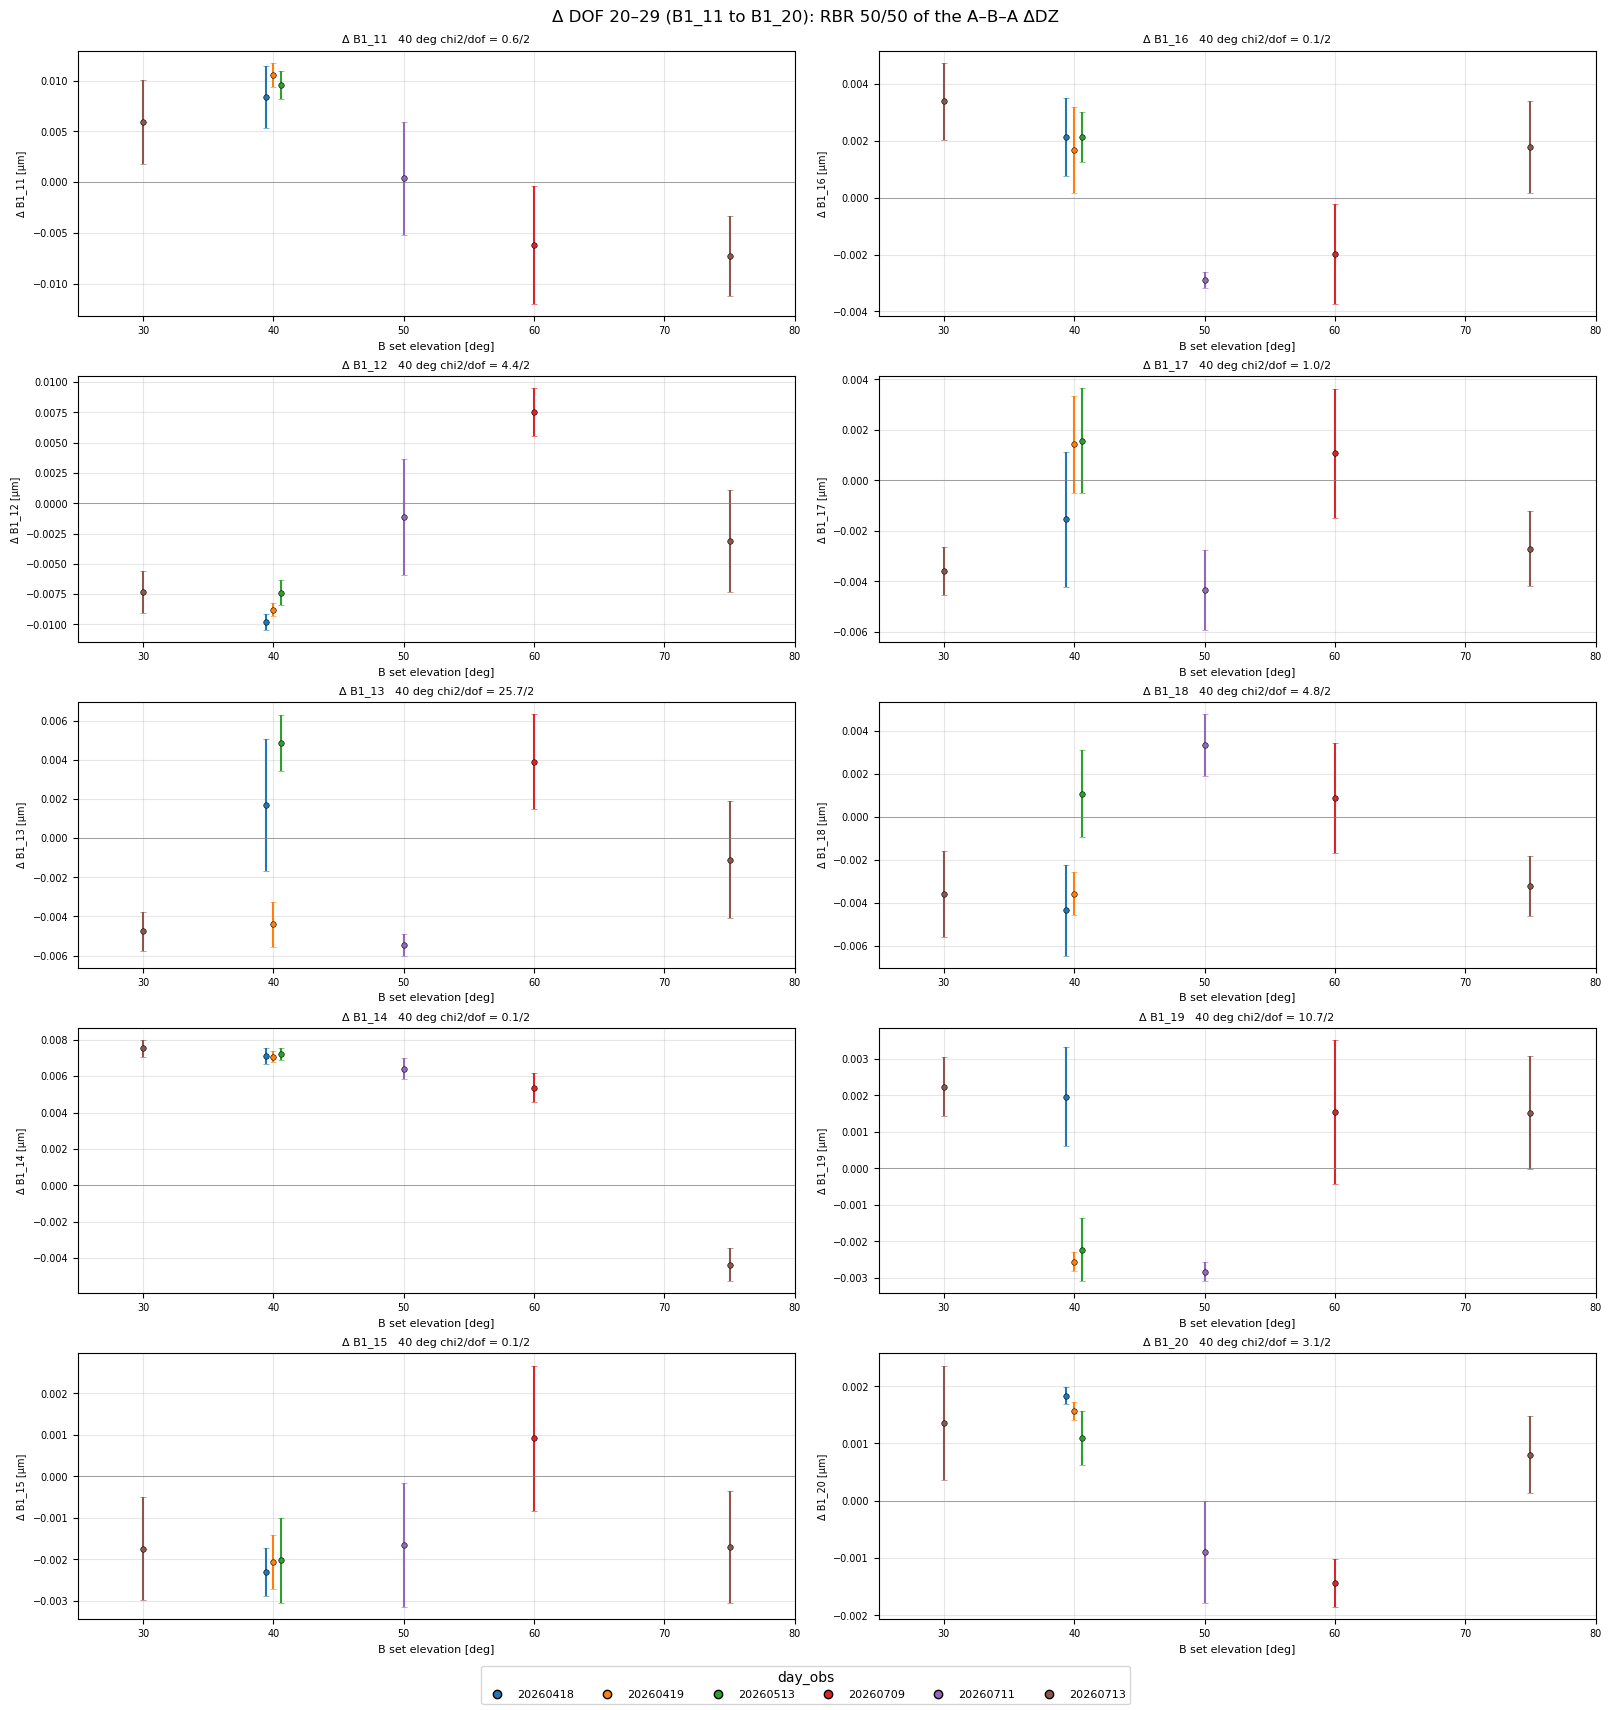

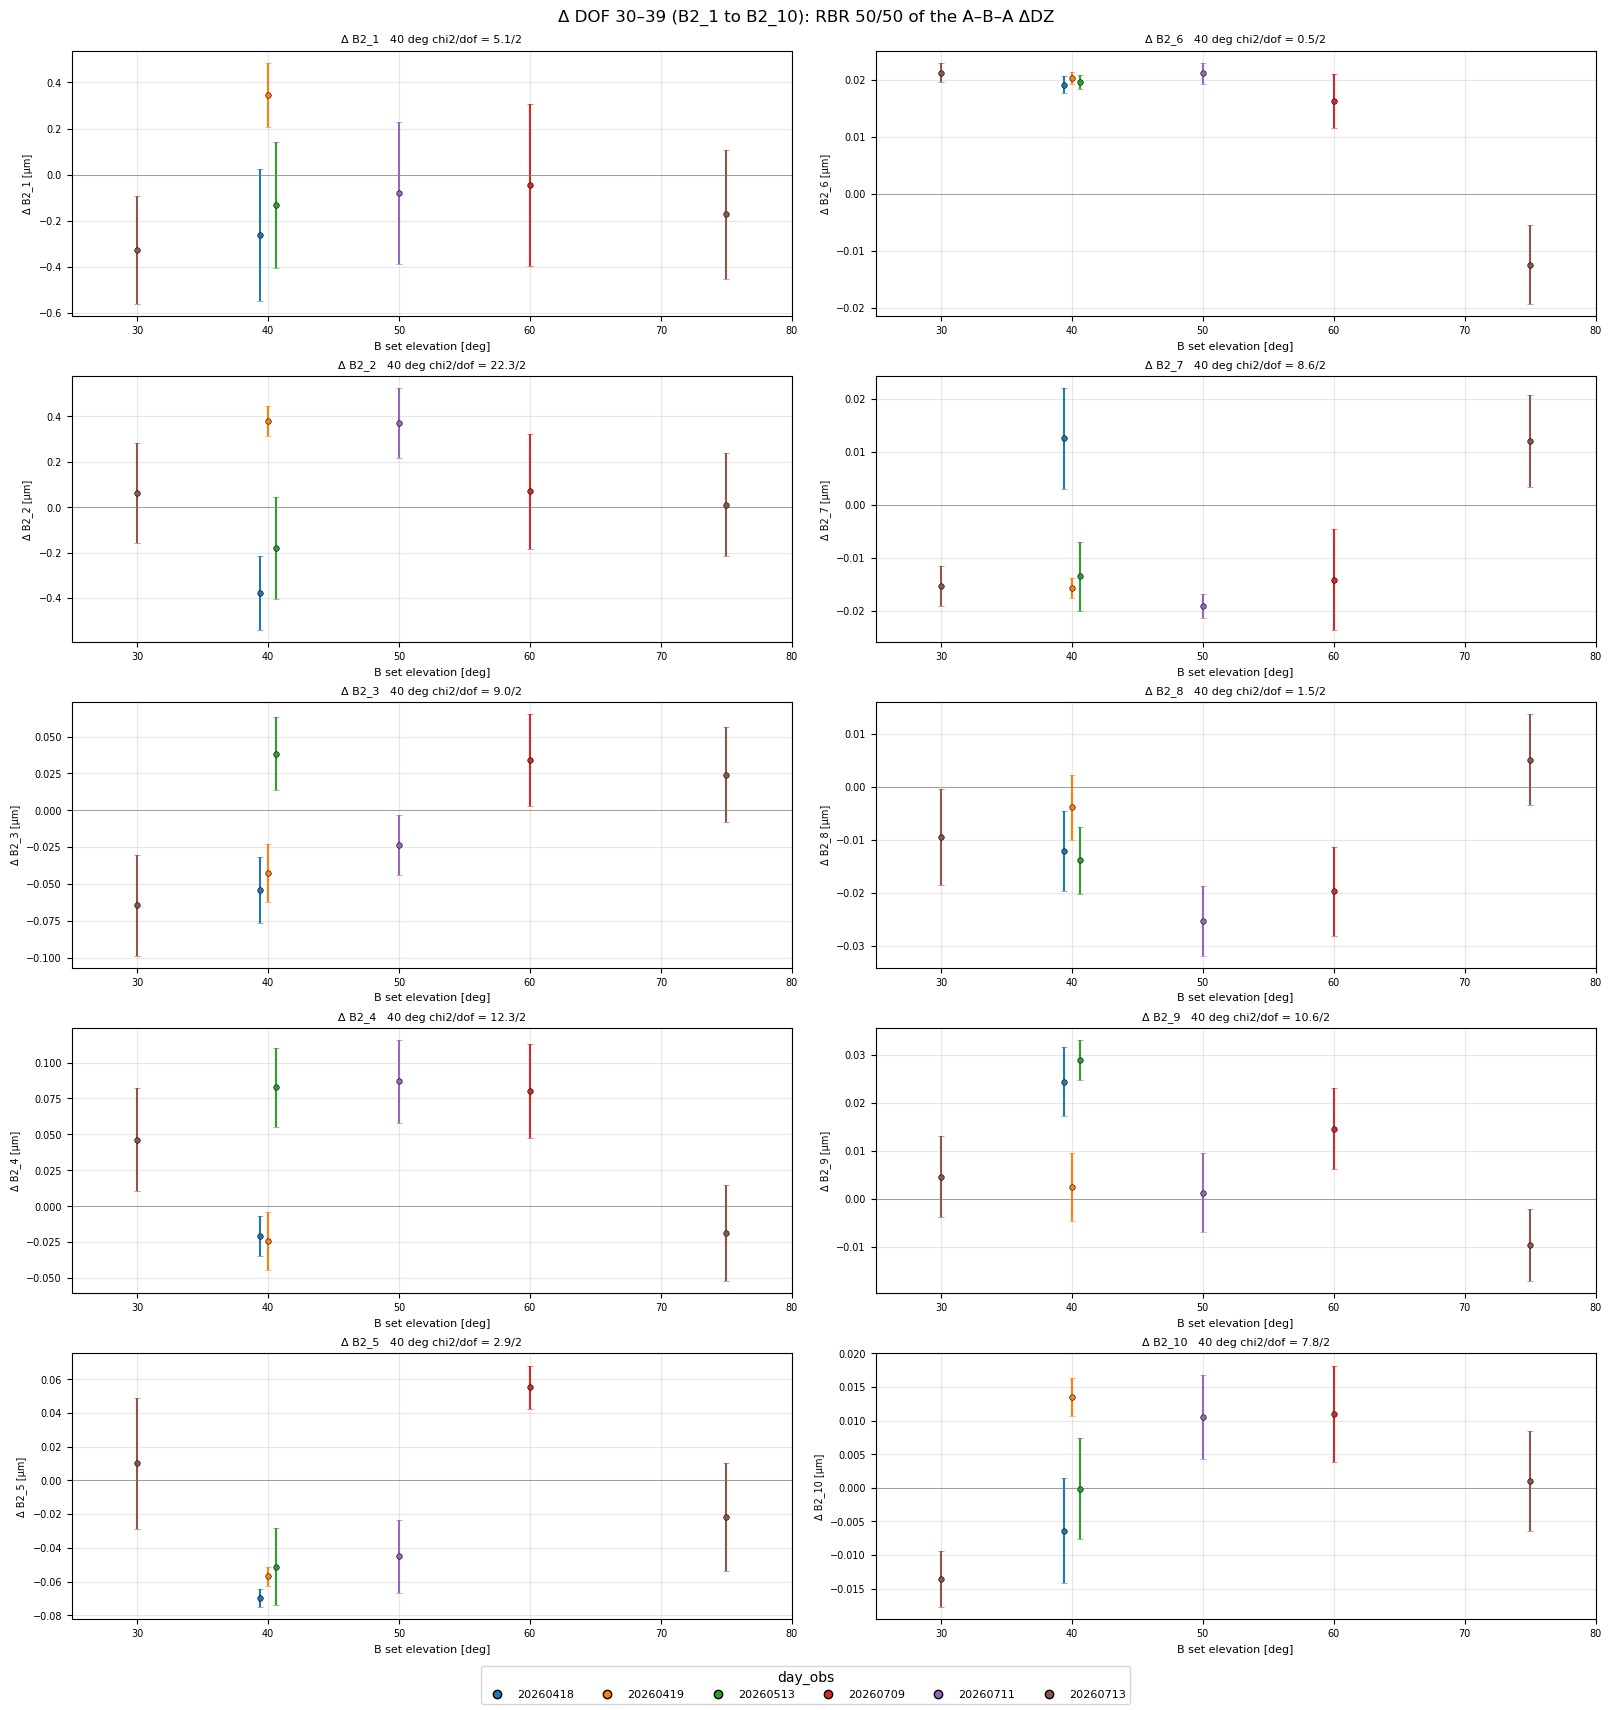

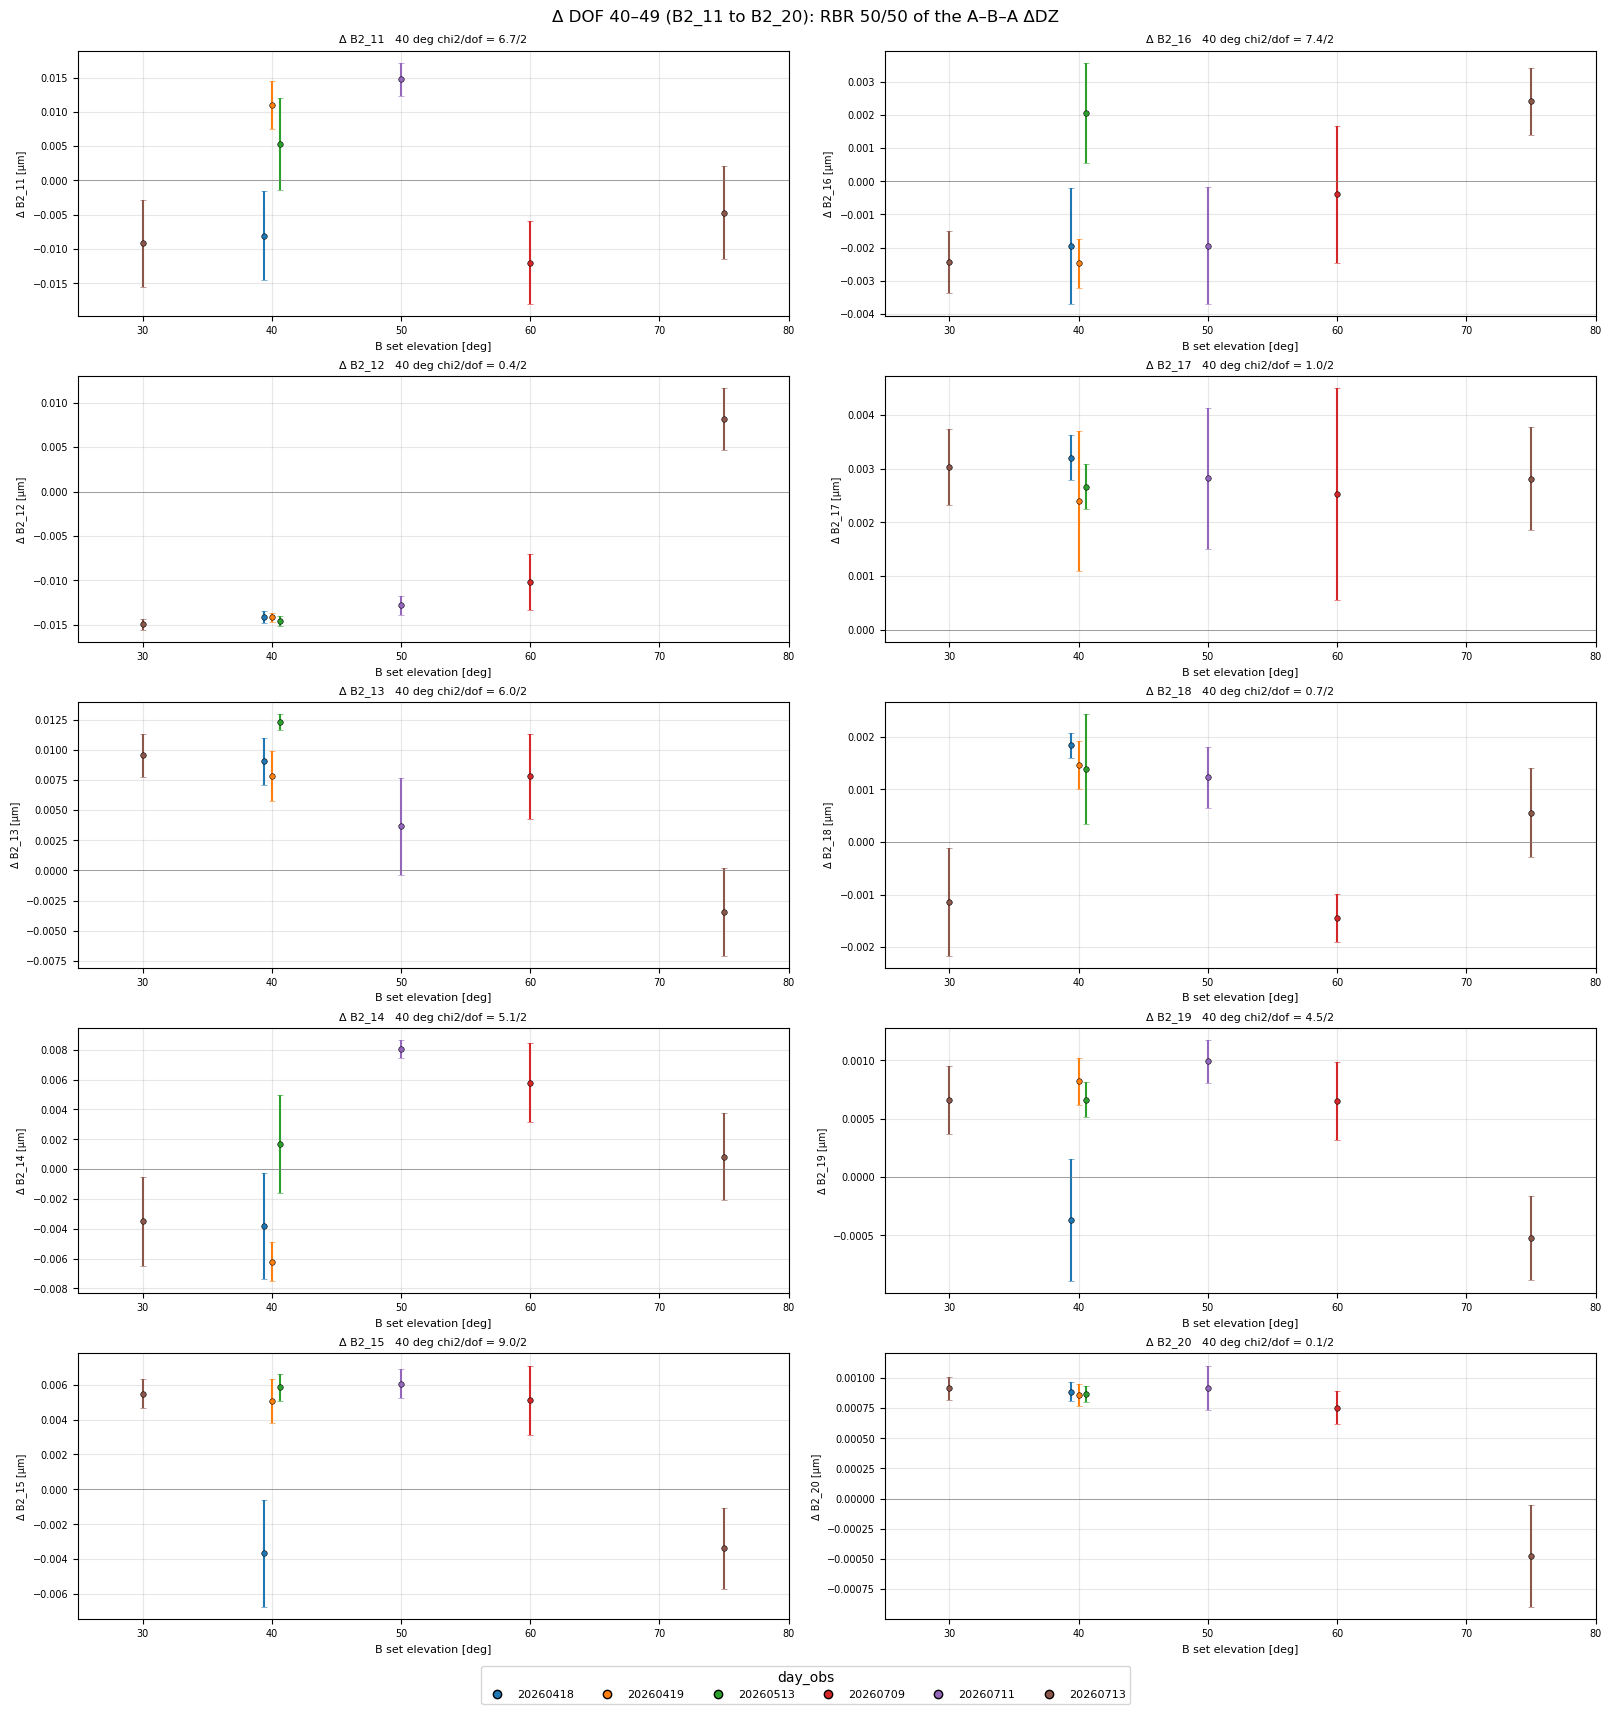

In [8]:
xoff = {n: o for n, o in zip([20260418, 20260419, 20260513], [-0.6, 0.0, 0.6])}


def chi2_40(vals, errs, bvals):
    m = bvals == 40.0
    x, e = vals[m], errs[m]
    if m.sum() < 2 or not np.all(e > 0):
        return np.nan
    w = 1 / e ** 2; mu = np.sum(w * x) / np.sum(w)
    return float(np.sum(w * (x - mu) ** 2))


bvals = np.array([L['b_value_deg'] for L in legs])


def panel(a_, getv, gete, title, ylabel):
    vals = np.array([getv(res[(L['night'], L['leg'])]) for L in legs])
    errs = np.array([gete(res[(L['night'], L['leg'])]) for L in legs])
    for L, y, e in zip(legs, vals, errs):
        a_.errorbar(L['b_value_deg'] + xoff.get(L['night'], 0.0), y, yerr=e, fmt='o', ms=4,
                    color=ncol[L['night']], mec='k', mew=0.4, capsize=2)
    a_.axhline(0, color='gray', lw=0.5); a_.grid(alpha=0.3)
    c2 = chi2_40(vals, errs, bvals)
    a_.set_title(f'{title}   40 deg chi2/dof = {c2:.1f}/2', fontsize=8)
    a_.set_ylabel(ylabel, fontsize=7); a_.tick_params(labelsize=7)
    a_.set_xlim(25, 80)


def legend_fig(fig):
    h = [plt.Line2D([], [], marker='o', ls='', color=ncol[n], mec='k', label=str(n)) for n in ncol]
    fig.legend(handles=h, loc='outside lower center', ncols=len(ncol), fontsize=8, title='day_obs')


ks = sorted({k for k, _ in KJ})
figs_dz = []
for p0 in range(0, len(iZs), J_PER_PAGE):
    js = iZs[p0:p0 + J_PER_PAGE]
    fig, axs = plt.subplots(len(js), len(ks), figsize=(22, 3.2 * len(js) + 1.2), layout='constrained',
                            squeeze=False)
    for ri, j in enumerate(js):
        for ci, k in enumerate(ks):
            ix = KJ.index((k, j))
            panel(axs[ri, ci], lambda r: r['dz'][ix], lambda r: r['dz_err'][ix], f'Δ DZ({k},{j})',
                  'Δ DZ [um of wavefront]')
            if ri == len(js) - 1:
                axs[ri, ci].set_xlabel('B set elevation [deg]', fontsize=8)
    fig.suptitle(f'A–B–A Δ DZ_kj vs 70 deg reference, j = {js[0]}..{js[-1]} (rows), k = 1..6 (columns)')
    legend_fig(fig); figs_dz.append(fig); plt.show()

figs_v = []
for p0 in range(0, N_VMODES_SHOW, VMODES_PER_PAGE):
    ms = list(range(p0, min(p0 + VMODES_PER_PAGE, N_VMODES_SHOW)))
    fig, axs = plt.subplots(3, 4, figsize=(20, 12), layout='constrained')
    for a_, m in zip(axs.flat, ms + [None] * (12 - len(ms))):
        if m is None:
            a_.set_visible(False); continue
        panel(a_, lambda r: r['v'][m], lambda r: r['v_err'][m], f'Δ v{m + 1}',
              'Δ v-mode [dimensionless]')
        a_.set_xlabel('B set elevation [deg]', fontsize=8)
    fig.suptitle(f'Δ v-modes v{ms[0] + 1}–v{ms[-1] + 1}: RBR 50/50 DOF of the A–B–A ΔDZ, '
                 'in the aos_state 50-DOF 50-mode v-modes')
    legend_fig(fig); figs_v.append(fig); plt.show()

figs_dof = []
for p0 in range(0, 50, DOF_PER_PAGE):
    fig, axs = plt.subplots(5, 2, figsize=(16, 17), layout='constrained')
    for a_, i in zip(axs.T.flat, range(p0, p0 + DOF_PER_PAGE)):
        panel(a_, lambda r: r['dof'][i], lambda r: r['dof_err'][i], f'Δ {LABELS_50DOF[i]}',
              f'Δ {LABELS_50DOF[i]} [{DOF_UNITS_50[i]}]')
        a_.set_xlabel('B set elevation [deg]', fontsize=8)
    fig.suptitle(f'Δ DOF {p0}–{p0 + DOF_PER_PAGE - 1} ({LABELS_50DOF[p0]} to {LABELS_50DOF[p0 + DOF_PER_PAGE - 1]}): '
                 'RBR 50/50 of the A–B–A ΔDZ')
    legend_fig(fig); figs_dof.append(fig); plt.show()

<a id='save'></a>
## Save

In [9]:
if SAVE:
    out = run.path / 'bounce_aba_optical_state.pdf'
    with PdfPages(str(out)) as pdf:
        for f in figs_dz + figs_v + figs_dof + [fig_split, fig_vg]:
            pdf.savefig(f, bbox_inches='tight')
    long = []
    for L in legs:
        r = res[(L['night'], L['leg'])]
        base = {'night': L['night'], 'leg': L['leg'], 'b_value_deg': L['b_value_deg']}
        long += [{**base, 'kind': 'DZ', 'name': f'DZ({k},{j})', 'unit': 'um', 'delta': r['dz'][a],
                  'err': r['dz_err'][a]} for a, (k, j) in enumerate(KJ)]
        long += [{**base, 'kind': 'vmode', 'name': f'v{m + 1}', 'unit': 'dimensionless',
                  'delta': r['v'][m], 'err': r['v_err'][m]} for m in range(50)]
        long += [{**base, 'kind': 'DOF', 'name': LABELS_50DOF[i], 'unit': DOF_UNITS_50[i],
                  'delta': r['dof'][i], 'err': r['dof_err'][i]} for i in range(50)]
    pd.DataFrame(long).to_csv(run.path / 'bounce_aba_optical_state.csv', index=False)
    vgm.to_csv(run.path / 'bounce_aba_variogram_diag.csv', index=False)
    key.to_csv(run.path / 'bounce_aba_v1_hexapod_split.csv', index=False)
    np.savez(run.path / 'bounce_aba_noise_model.npz', SIG_W=SIG_W, SIG_R=SIG_R, ALPHA=ALPHA,
             kj=np.array(KJ))
    print(f'wrote {out}: {len(figs_dz)} DZ, {len(figs_v)} v-mode, {len(figs_dof)} DOF pages, '
          'then the hexapod-split and noise-model pages')

wrote /sdf/group/rubin/u/roodman/LSST/rubin-work/studies/aos/bounce/20261029_aba_optical_state/bounce_aba_optical_state.pdf: 6 DZ, 3 v-mode, 5 DOF pages, then the hexapod-split and noise-model pages
